In [ ]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 1
# Setup + Fixed Split + DataLoader + Model + Functions
# Google Drive "Add shortcut to Drive" Compatible
# ============================================================


# ============================================================
# 0. INSTALL PACKAGES
# ============================================================

!pip -q install -U timm fvcore scipy statsmodels openpyxl


# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. EXPERIMENTAL CONFIGURATION
# SAME AS ORIGINAL
# ============================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50

NUM_WORKERS = 0


# ============================================================
# 3. MODEL INFORMATION
# ============================================================

MODEL_NAME = "ConvNeXt-Tiny"

TIMM_MODEL_NAME = (
    "convnext_tiny.fb_in22k_ft_in1k"
)


# ============================================================
# 4. CLASS INFORMATION
# ============================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ============================================================
# 5. FIND ACTUAL Brishty_ml SHORTCUT TARGET
# ============================================================

print("=" * 75)
print("LOCATING Brishty_ml SHORTCUT TARGET")
print("=" * 75)


BRISHTY_ROOT = None


# ------------------------------------------------------------
# A. First try normal MyDrive shortcut path
# ------------------------------------------------------------

NORMAL_ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml"
)


if NORMAL_ROOT.exists():

    normal_sevd = (
        NORMAL_ROOT /
        "sevd_final"
    )

    normal_results = (
        NORMAL_ROOT /
        "reviewer_final_results"
    )


    if (
        normal_sevd.is_dir()
        and
        normal_results.is_dir()
    ):

        BRISHTY_ROOT = NORMAL_ROOT

        print(
            "Shortcut is directly accessible through MyDrive."
        )


# ------------------------------------------------------------
# B. Search .shortcut-targets-by-id
# ------------------------------------------------------------

if BRISHTY_ROOT is None:

    SHORTCUT_TARGET_ROOT = Path(
        "/content/drive/.shortcut-targets-by-id"
    )


    if not SHORTCUT_TARGET_ROOT.exists():

        raise FileNotFoundError(
            "Google Drive shortcut target directory "
            "was not mounted."
        )


    print(
        "Searching .shortcut-targets-by-id ..."
    )


    # Each item here is usually a shortcut target ID
    for target_root in SHORTCUT_TARGET_ROOT.iterdir():

        if not target_root.is_dir():
            continue


        # ---------------------------------------------
        # Case 1:
        # target root itself is Brishty_ml
        # ---------------------------------------------

        candidate_sevd = (
            target_root /
            "sevd_final"
        )

        candidate_results = (
            target_root /
            "reviewer_final_results"
        )


        if (
            candidate_sevd.is_dir()
            and
            candidate_results.is_dir()
        ):

            BRISHTY_ROOT = target_root

            break


        # ---------------------------------------------
        # Case 2:
        # Brishty_ml is nested inside target
        # ---------------------------------------------

        for candidate_root in target_root.rglob("*"):

            if not candidate_root.is_dir():
                continue


            candidate_sevd = (
                candidate_root /
                "sevd_final"
            )

            candidate_results = (
                candidate_root /
                "reviewer_final_results"
            )


            if (
                candidate_sevd.is_dir()
                and
                candidate_results.is_dir()
            ):

                BRISHTY_ROOT = candidate_root

                break


        if BRISHTY_ROOT is not None:
            break


# ============================================================
# 6. FINAL SHORTCUT SAFETY CHECK
# ============================================================

if BRISHTY_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the shared Brishty_ml folder.\n\n"
        "Expected inside the shared folder:\n"
        "Brishty_ml/\n"
        "  sevd_final/\n"
        "  reviewer_final_results/"
    )


print(
    "\nBrishty_ml shortcut target found:"
)

print(
    BRISHTY_ROOT
)


# ============================================================
# 7. DATASET + OUTPUT PATH
# ============================================================

DATASET_DIR = (
    BRISHTY_ROOT /
    "sevd_final" /
    "images"
)


OUTPUT_DIR = (
    BRISHTY_ROOT /
    "reviewer_final_results"
)


print(
    "\nDATASET_DIR:"
)

print(
    DATASET_DIR
)


print(
    "\nOUTPUT_DIR:"
)

print(
    OUTPUT_DIR
)


# ============================================================
# 8. DATASET SAFETY CHECK
# ============================================================

if not DATASET_DIR.is_dir():

    raise FileNotFoundError(
        f"Dataset folder not found:\n"
        f"{DATASET_DIR}"
    )


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )


    if not class_folder.is_dir():

        raise FileNotFoundError(
            f"Class folder not found:\n"
            f"{class_folder}"
        )


print(
    "\nDataset and both class folders found."
)


# ============================================================
# 9. OUTPUT PATHS
# ============================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)


FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)


TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    "03_ConvNeXt_Tiny"
)


MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)


HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)


FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)


PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)


METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [
    MODEL_OUTPUT_DIR,
    MODEL_DIR,
    HISTORY_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    METRIC_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 10. DEVICE + REPRODUCIBILITY
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


def set_seed(seed=42):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# ============================================================
# 11. COLLECT IMAGES
# ============================================================

def collect_images(
    dataset_dir
):

    image_paths = []

    labels = []


    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )


        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()


            for file_name in sorted(files):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_paths.append(
                        str(
                            Path(root) /
                            file_name
                        )
                    )


                    labels.append(
                        CLASS_TO_IDX[
                            class_name
                        ]
                    )


    return (
        np.asarray(
            image_paths
        ),

        np.asarray(
            labels,
            dtype=np.int64
        )
    )


# ============================================================
# 12. LOAD EXISTING FIXED SPLIT
# CREATE ONLY IF IT DOES NOT EXIST
# ============================================================

if (
    FOLD_CSV_PATH.exists()
    and
    TEST_CSV_PATH.exists()
):

    print(
        "\nExisting fixed split files found."
    )


    development_df = pd.read_csv(
        FOLD_CSV_PATH
    )


    test_df = pd.read_csv(
        TEST_CSV_PATH
    )


else:

    print(
        "\nFixed split files were not found."
    )

    print(
        "Creating fixed split using the same settings."
    )


    all_image_paths, all_labels = (
        collect_images(
            DATASET_DIR
        )
    )


    if len(all_image_paths) == 0:

        raise RuntimeError(
            "No images were found."
        )


    (
        development_paths,
        test_paths,
        development_labels,
        test_labels
    ) = train_test_split(

        all_image_paths,
        all_labels,

        test_size=0.15,

        random_state=SEED,

        stratify=all_labels,

        shuffle=True
    )


    development_fold_ids = np.zeros(
        len(development_paths),
        dtype=np.int64
    )


    stratified_kfold = StratifiedKFold(

        n_splits=N_FOLDS,

        shuffle=True,

        random_state=SEED
    )


    for fold_number, (
        _,
        validation_indices
    ) in enumerate(

        stratified_kfold.split(
            development_paths,
            development_labels
        ),

        start=1
    ):

        development_fold_ids[
            validation_indices
        ] = fold_number


    development_df = pd.DataFrame({

        "image_path":
            development_paths,

        "label":
            development_labels.astype(int),

        "class_name": [
            CLASS_NAMES[int(label)]
            for label in
            development_labels
        ],

        "dataset_role":
            "development",

        "fold_id":
            development_fold_ids
    })


    test_df = pd.DataFrame({

        "image_path":
            test_paths,

        "label":
            test_labels.astype(int),

        "class_name": [
            CLASS_NAMES[int(label)]
            for label in
            test_labels
        ],

        "dataset_role":
            "test",

        "fold_id":
            0
    })


    complete_split_df = pd.concat(
        [
            development_df,
            test_df
        ],
        ignore_index=True
    )


    development_df.to_csv(
        FOLD_CSV_PATH,
        index=False
    )


    test_df.to_csv(
        TEST_CSV_PATH,
        index=False
    )


    complete_split_df.to_csv(
        COMPLETE_SPLIT_PATH,
        index=False
    )


# ============================================================
# 13. REPAIR OLD IMAGE PATH PREFIX IF NEEDED
# DOES NOT CHANGE FOLD ASSIGNMENT
# ============================================================

def repair_image_path(
    old_path
):

    old_path = str(
        old_path
    )


    if Path(
        old_path
    ).exists():

        return old_path


    normalized = (
        old_path
        .replace(
            "\\",
            "/"
        )
    )


    marker = (
        "sevd_final/images/"
    )


    if marker not in normalized:

        return old_path


    relative_path = (
        normalized
        .split(
            marker,
            1
        )[1]
    )


    repaired_path = (
        DATASET_DIR /
        relative_path
    )


    return str(
        repaired_path
    )


development_df[
    "image_path"
] = development_df[
    "image_path"
].apply(
    repair_image_path
)


test_df[
    "image_path"
] = test_df[
    "image_path"
].apply(
    repair_image_path
)


# ============================================================
# 14. STANDARDIZE DATA TYPES
# ============================================================

development_df[
    "label"
] = development_df[
    "label"
].astype(
    int
)


development_df[
    "fold_id"
] = development_df[
    "fold_id"
].astype(
    int
)


test_df[
    "label"
] = test_df[
    "label"
].astype(
    int
)


available_folds = sorted(
    development_df[
        "fold_id"
    ]
    .unique()
    .tolist()
)


if available_folds != [
    1,
    2,
    3,
    4,
    5
]:

    raise ValueError(
        f"Unexpected fold IDs: "
        f"{available_folds}"
    )


# ============================================================
# 15. VERIFY ALL SAVED IMAGE PATHS
# ============================================================

missing_development = (

    ~development_df[
        "image_path"
    ].apply(
        lambda path:
            Path(path).exists()
    )

).sum()


missing_test = (

    ~test_df[
        "image_path"
    ].apply(
        lambda path:
            Path(path).exists()
    )

).sum()


print(
    "\nMissing development images:",
    int(
        missing_development
    )
)


print(
    "Missing test images:",
    int(
        missing_test
    )
)


if missing_development > 0:

    raise FileNotFoundError(
        f"{missing_development} development "
        f"images are missing."
    )


if missing_test > 0:

    raise FileNotFoundError(
        f"{missing_test} test images are missing."
    )


# ============================================================
# 16. SAVE REPAIRED PATHS
# Fold IDs/labels remain exactly the same
# ============================================================

development_df.to_csv(
    FOLD_CSV_PATH,
    index=False
)


test_df.to_csv(
    TEST_CSV_PATH,
    index=False
)


complete_split_df = pd.concat(
    [
        development_df,
        test_df
    ],
    ignore_index=True
)


complete_split_df.to_csv(
    COMPLETE_SPLIT_PATH,
    index=False
)


# ============================================================
# 17. PREPROCESSING
# SAME AS ORIGINAL
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]


IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    transforms.RandomRotation(
        degrees=36,
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(
            0.90,
            1.10
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


evaluation_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 18. DATASET CLASS
# ============================================================

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = str(
            row[
                "image_path"
            ]
        )


        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = opened_image.convert(
                    "RGB"
                )


        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ============================================================
# 19. DATALOADER
# ============================================================

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )


    generator = torch.Generator()

    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=(
            torch.cuda.is_available()
        ),

        persistent_workers=False,

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


# ============================================================
# 20. FIXED TEST LOADER
# ============================================================

test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ============================================================
# 21. MODEL DEFINITION
# ============================================================

class ConvNeXtTinyBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="avg"
        )


        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )


        features = self.dropout(
            features
        )


        logits = self.binary_output(
            features
        )


        return logits.squeeze(
            dim=1
        )


def build_convnext_tiny_model():

    model = ConvNeXtTinyBinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ============================================================
# 22. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()

    model.backbone.eval()


    total_loss = 0.0

    all_labels = []

    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/{EPOCHS} "
            f"Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        loss.backward()

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        total_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(
            labels
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(
            predictions
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    return {

        "loss":
            float(
                total_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    all_labels,
                    all_predictions
                )
            )
    }


# ============================================================
# 23. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    total_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(
        dataloader,
        desc=description,
        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            total_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(
                labels
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(
                probabilities
                .cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(
                predictions
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    confusion = confusion_matrix(

        labels_array,

        predictions_array,

        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                total_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


# ============================================================
# 24. SAFETY CHECK
# ============================================================

check_train_df = development_df[

    development_df[
        "fold_id"
    ] != 1

].reset_index(
    drop=True
)


check_dataset, check_loader = (
    create_dataloader(

        dataframe=check_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            1
        )
    )
)


sample_batch = next(
    iter(
        check_loader
    )
)


verification_model, _, _ = (
    build_convnext_tiny_model()
)


verification_model.eval()


with torch.no_grad():

    dummy_output = verification_model(

        sample_batch[
            "image"
        ][:2].to(
            DEVICE
        )
    )


backbone_trainable_parameters = sum(

    parameter.numel()

    for parameter in
    verification_model.backbone.parameters()

    if parameter.requires_grad
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)


assert dummy_output.shape == (
    2,
)


assert backbone_trainable_parameters == 0


# ============================================================
# 25. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 75
)

print(
    "CONVNEXT-TINY CELL 1 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Device:",
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(
            0
        )
    )


print(
    "\nActual Brishty_ml:"
)

print(
    BRISHTY_ROOT
)


print(
    "\nDataset:"
)

print(
    DATASET_DIR
)


print(
    "\nOutput:"
)

print(
    OUTPUT_DIR
)


print(
    "\nDevelopment images:",
    len(
        development_df
    )
)


print(
    "Test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


print(
    "Missing development images:",
    int(
        missing_development
    )
)


print(
    "Missing test images:",
    int(
        missing_test
    )
)


print(
    "Batch shape:",
    sample_batch[
        "image"
    ].shape
)


print(
    "Dummy output shape:",
    dummy_output.shape
)


print(
    "Backbone frozen:",
    backbone_trainable_parameters == 0
)


print(
    "\nModel output folder:"
)

print(
    MODEL_OUTPUT_DIR
)


del verification_model
del check_loader
del check_dataset


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 3.9 MB/s eta 0:00:00
Mounted at /content/drive
LOCATING Brishty_ml SHORTCUT TARGET
Shortcut is directly accessible through MyDrive.

Brishty_ml shortcut target found:
/content/drive/MyDrive/Brishty_ml

DATASET_DIR:
/content/drive/MyDrive/Brishty_ml/sevd_final/images

OUTPUT_DIR:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results

Dataset and both class folders found.

Existing fixed split files found.

Missing development images: 0
Missing test images: 0


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


CONVNEXT-TINY CELL 1 COMPLETED
Device: cuda
GPU: Tesla T4

Actual Brishty_ml:
/content/drive/MyDrive/Brishty_ml

Dataset:
/content/drive/MyDrive/Brishty_ml/sevd_final/images

Output:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results

Development images: 6299
Test images: 1112
Fold IDs: [1, 2, 3, 4, 5]
Missing development images: 0
Missing test images: 0
Batch shape: torch.Size([32, 3, 224, 224])
Dummy output shape: torch.Size([2])
Backbone frozen: True

Model output folder:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny



STARTING ConvNeXt-Tiny FOLD 5/5
Training images: 5040
Validation images: 1259
Independent test images: 1112


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 | Epoch 01/30 - loss: 0.5150 - accuracy: 0.7496 - val_loss: 0.3184 - val_accuracy: 0.9230


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 | Epoch 30/30 - loss: 0.0373 - accuracy: 0.9903 - val_loss: 0.0234 - val_accuracy: 0.9952


Fold 5 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

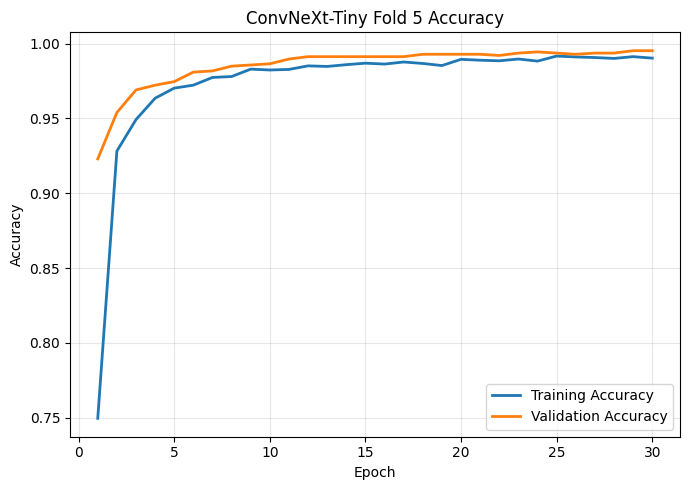

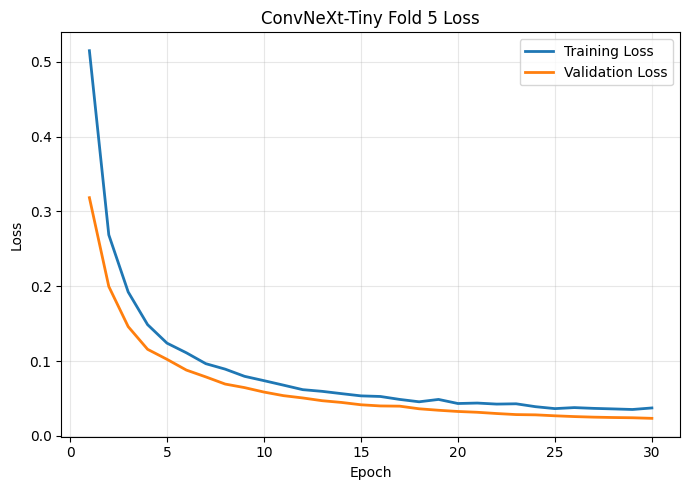


Fold 5 training time: 120.77 minutes

Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ConvNeXt-Tiny,5,validation,0.023357,0.995234,0.998316,0.991639,0.994966,0.999909,660,1,5,593,7246.424716,120.773745



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ConvNeXt-Tiny,5,test,0.025109,0.994604,0.994318,0.994318,0.994318,0.999831,581,3,3,525,7246.424716,120.773745



Saved model: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/saved_models/ConvNeXt-Tiny_fold_5.pth
Saved history: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/training_history/ConvNeXt-Tiny_fold_5_history.csv
Saved accuracy graph: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/figures/ConvNeXt-Tiny_fold_5_accuracy.png
Saved loss graph: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/figures/ConvNeXt-Tiny_fold_5_loss.png
Saved validation predictions: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/predictions/ConvNeXt-Tiny_fold_5_validation_predictions.csv
Saved test predictions: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/predictions/ConvNeXt-Tiny_fold_5_test_predictions.csv
Saved summary: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/metrics/ConvNeXt-Tiny_fold_5_summary.csv

ConvNeXt-Tiny FOLD 5

In [ ]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 2
# TRAIN ONLY FOLD 5
# Same original training/evaluation/saving logic
# ============================================================


# ============================================================
# 1. SAVE HISTORY AND GRAPHS
# ============================================================

def save_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    history_path = (
        HISTORY_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )


    # ========================================================
    # ACCURACY GRAPH
    # ========================================================

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Accuracy"
    )

    plt.title(
        f"ConvNeXt-Tiny Fold {fold_number} Accuracy"
    )

    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_accuracy.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    # ========================================================
    # LOSS GRAPH
    # ========================================================

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"ConvNeXt-Tiny Fold {fold_number} Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_loss.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    return (
        history_df,
        history_path,
        accuracy_path,
        loss_path
    )


# ============================================================
# 2. SAVE PREDICTIONS
# ============================================================

def save_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [
            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (
        prediction_df[
            "label"
        ]
        ==
        prediction_df[
            "predicted_label"
        ]
    )


    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return prediction_path


# ============================================================
# 3. SAVE MODEL
# ============================================================

def save_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}.pth"
    )


    torch.save(

        {

            "model_name":
                MODEL_NAME,

            "timm_model_name":
                TIMM_MODEL_NAME,

            "fold":
                fold_number,

            "image_size":
                IMG_SIZE,

            "batch_size":
                BATCH_SIZE,

            "epochs":
                EPOCHS,

            "learning_rate":
                LEARNING_RATE,

            "threshold":
                THRESHOLD,

            "class_names":
                CLASS_NAMES,

            "class_to_idx":
                CLASS_TO_IDX,

            "model_state_dict":
                model.state_dict()
        },

        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. CREATE SUMMARY ROW
# ============================================================

def create_summary_row(
    result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            fold_number,

        "dataset":
            dataset_name,

        "loss":
            result[
                "loss"
            ],

        "accuracy":
            result[
                "accuracy"
            ],

        "precision":
            result[
                "precision"
            ],

        "recall":
            result[
                "recall"
            ],

        "f1_score":
            result[
                "f1_score"
            ],

        "auc":
            result[
                "auc"
            ],

        "true_negative":
            result[
                "true_negative"
            ],

        "false_positive":
            result[
                "false_positive"
            ],

        "false_negative":
            result[
                "false_negative"
            ],

        "true_positive":
            result[
                "true_positive"
            ],

        "training_time_seconds":
            training_time_seconds,

        "training_time_minutes":
            training_time_seconds /
            60
    }


# ============================================================
# 5. TRAIN ONLY FOLD 5
# ============================================================

all_summary_rows = []


for fold_number in range(
    5,
    6
):

    print(
        "\n" +
        "=" * 80
    )


    print(
        f"STARTING ConvNeXt-Tiny "
        f"FOLD {fold_number}/{N_FOLDS}"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # FOLD TRAINING DATA
    # ========================================================

    fold_train_df = development_df[

        development_df[
            "fold_id"
        ] != fold_number

    ].reset_index(
        drop=True
    )


    # ========================================================
    # FOLD VALIDATION DATA
    # ========================================================

    fold_validation_df = development_df[

        development_df[
            "fold_id"
        ] == fold_number

    ].reset_index(
        drop=True
    )


    print(
        "Training images:",
        len(
            fold_train_df
        )
    )


    print(
        "Validation images:",
        len(
            fold_validation_df
        )
    )


    print(
        "Independent test images:",
        len(
            test_df
        )
    )


    # ========================================================
    # TRAIN DATALOADER
    # ========================================================

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # ========================================================
    # VALIDATION DATALOADER
    # ========================================================

    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # ========================================================
    # SAME FOLD-SPECIFIC SEED
    # ========================================================

    set_seed(
        SEED +
        fold_number
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # ========================================================
    # BUILD FRESH CONVNEXT-TINY
    # ========================================================

    model, criterion, optimizer = (
        build_convnext_tiny_model()
    )


    history_dictionary = {

        "loss":
            [],

        "accuracy":
            [],

        "val_loss":
            [],

        "val_accuracy":
            []
    }


    # ========================================================
    # START TRAINING TIMER
    # ========================================================

    training_start_time = (
        time.perf_counter()
    )


    # ========================================================
    # ACTUAL 30-EPOCH TRAINING
    # ========================================================

    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        training_result = (
            train_one_epoch(

                model=model,

                dataloader=(
                    fold_train_loader
                ),

                criterion=criterion,

                optimizer=optimizer,

                epoch_number=(
                    epoch_number
                )
            )
        )


        validation_result = (
            evaluate_model(

                model=model,

                dataloader=(
                    fold_validation_loader
                ),

                criterion=criterion,

                description=(
                    f"Epoch "
                    f"{epoch_number:02d}/"
                    f"{EPOCHS} Validation"
                )
            )
        )


        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: "
            f"{training_result['loss']:.4f} - "
            f"accuracy: "
            f"{training_result['accuracy']:.4f} - "
            f"val_loss: "
            f"{validation_result['loss']:.4f} - "
            f"val_accuracy: "
            f"{validation_result['accuracy']:.4f}"
        )


    # ========================================================
    # TRAINING TIME
    # ========================================================

    training_time_seconds = (
        time.perf_counter() -
        training_start_time
    )


    # ========================================================
    # FINAL VALIDATION EVALUATION
    # ========================================================

    final_validation_result = (
        evaluate_model(

            model=model,

            dataloader=(
                fold_validation_loader
            ),

            criterion=criterion,

            description=(
                f"Fold {fold_number} "
                f"Final Validation"
            )
        )
    )


    # ========================================================
    # INDEPENDENT TEST EVALUATION
    # ========================================================

    final_test_result = (
        evaluate_model(

            model=model,

            dataloader=test_loader,

            criterion=criterion,

            description=(
                f"Fold {fold_number} "
                f"Independent Test"
            )
        )
    )


    # ========================================================
    # SAVE HISTORY + GRAPHS
    # ========================================================

    (
        history_df,
        history_path,
        accuracy_path,
        loss_path
    ) = save_history_and_graphs(

        history_dictionary,

        fold_number
    )


    # ========================================================
    # SAVE VALIDATION PREDICTIONS
    # ========================================================

    validation_prediction_path = (
        save_predictions(

            final_validation_result,

            fold_number,

            "validation"
        )
    )


    # ========================================================
    # SAVE TEST PREDICTIONS
    # ========================================================

    test_prediction_path = (
        save_predictions(

            final_test_result,

            fold_number,

            "test"
        )
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    checkpoint_path = (
        save_checkpoint(

            model,

            fold_number
        )
    )


    # ========================================================
    # VALIDATION SUMMARY
    # ========================================================

    validation_summary = (
        create_summary_row(

            final_validation_result,

            fold_number,

            "validation",

            training_time_seconds
        )
    )


    # ========================================================
    # TEST SUMMARY
    # ========================================================

    test_summary = (
        create_summary_row(

            final_test_result,

            fold_number,

            "test",

            training_time_seconds
        )
    )


    fold_summary_df = pd.DataFrame(
        [
            validation_summary,
            test_summary
        ]
    )


    # ========================================================
    # SAVE CURRENT FOLD SUMMARY
    # ========================================================

    fold_summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_"
        f"{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_summary_rows.extend(
        [
            validation_summary,
            test_summary
        ]
    )


    # ========================================================
    # DISPLAY CURRENT FOLD RESULTS
    # ========================================================

    print(
        f"\nFold {fold_number} "
        f"training time: "
        f"{training_time_seconds / 60:.2f} minutes"
    )


    print(
        "\nValidation result:"
    )


    display(

        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent test result:"
    )


    display(

        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved model:",
        checkpoint_path
    )


    print(
        "Saved history:",
        history_path
    )


    print(
        "Saved accuracy graph:",
        accuracy_path
    )


    print(
        "Saved loss graph:",
        loss_path
    )


    print(
        "Saved validation predictions:",
        validation_prediction_path
    )


    print(
        "Saved test predictions:",
        test_prediction_path
    )


    print(
        "Saved summary:",
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )


    print(
        f"ConvNeXt-Tiny "
        f"FOLD {fold_number} COMPLETED"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # CLEAN MEMORY
    # ========================================================

    del model

    del criterion

    del optimizer

    del fold_train_loader

    del fold_validation_loader

    del fold_train_dataset

    del fold_validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. FINAL OUTPUT FOR THIS RUN
# ============================================================

print(
    "\n" +
    "=" * 80
)


print(
    "CONVNEXT-TINY FOLD 5 COMPLETED"
)


print(
    "=" * 80
)


print(
    "\nFold 1–4 were NOT retrained."
)


print(
    "Only Fold 5 was trained."
)


print(
    "\nAll Fold 5 outputs were saved inside:"
)


print(
    MODEL_OUTPUT_DIR
)

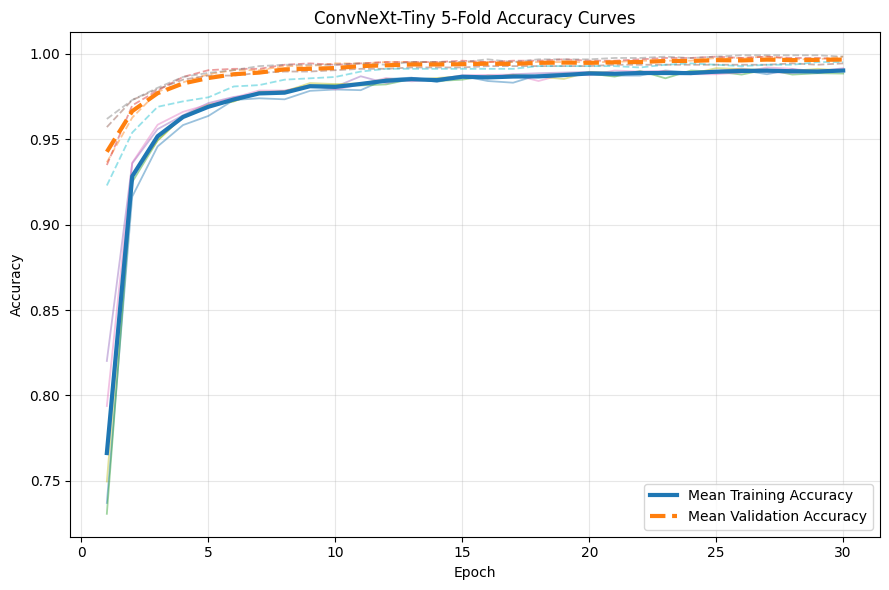

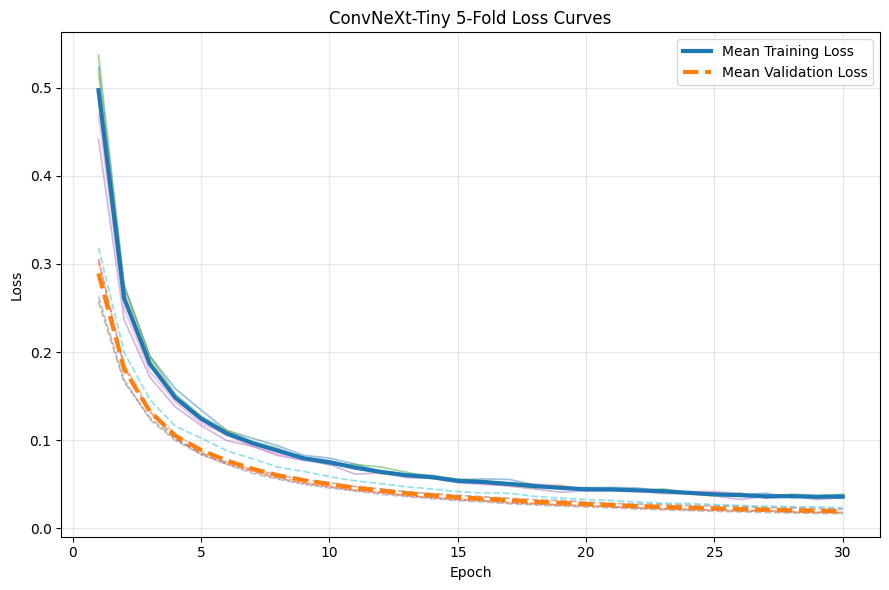

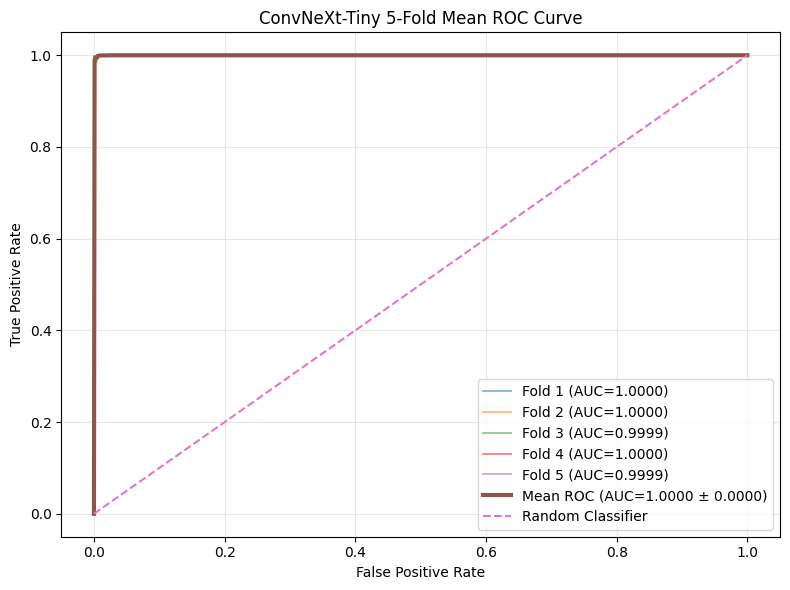

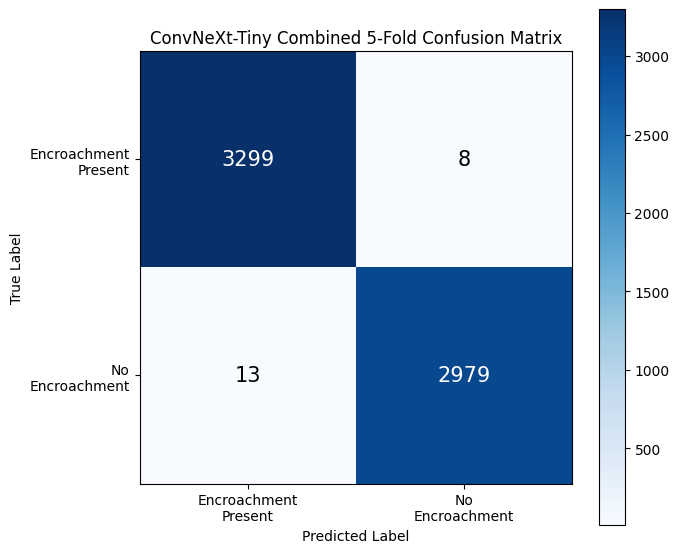


CONVNEXT-TINY FINAL ANALYSIS COMPLETED

Performance Mean ± SD:


,Model,Loss,Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUC
0,ConvNeXt-Tiny,0.02 ± 0.00,99.67 ± 0.18,99.73 ± 0.22,99.57 ± 0.30,99.65 ± 0.19,1.00 ± 0.00



Accuracy 95% CI:


,Model,Mean Accuracy (%),Standard Deviation (%),Standard Error (%),95% CI Lower (%),95% CI Upper (%),Paper Format
0,ConvNeXt-Tiny,99.666591,0.181055,0.08097,99.441782,99.8914,99.67% (99.44%–99.89%)



Training Time:


,Model,Mean Training Time (minutes),Training Time SD (minutes),Mean ± SD
0,ConvNeXt-Tiny,116.187559,32.26838,116.19 ± 32.27



Computational Complexity:


,Model,Parameters (M),Trainable Parameters (M),Non-trainable Parameters (M),GFLOPs,Model Size (MB),Inference Time (ms/image),FPS,Training Time (minutes)
0,ConvNeXt-Tiny,27.820897,0.000769,27.820128,4.46967,106.201751,20.841129,47.982046,116.19 ± 32.27



All results saved inside:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/final_standard_paper_results


In [ ]:
# ============================================================
# CONVNEXT-TINY — COMPLETE CELL 3
# Final Paper-Ready 5-Fold Analysis
# ============================================================

from scipy import stats
from fvcore.nn import FlopCountAnalysis


# ============================================================
# 1. FINAL FOLDERS
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. READ FIVE-FOLD VALIDATION RESULTS
# ============================================================

validation_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_summary.csv"
    )


    if not summary_path.exists():

        raise FileNotFoundError(
            f"Missing fold summary:\n"
            f"{summary_path}"
        )


    summary_df = pd.read_csv(
        summary_path
    )


    current_validation = summary_df[
        summary_df["dataset"] ==
        "validation"
    ]


    if len(current_validation) != 1:

        raise ValueError(
            f"Fold {fold_number} validation row error."
        )


    row = (
        current_validation
        .iloc[0]
        .to_dict()
    )

    row["fold"] = fold_number

    validation_rows.append(
        row
    )


validation_metrics_df = pd.DataFrame(
    validation_rows
)


# ============================================================
# 3. PERFORMANCE MEAN ± SD TABLE
# ============================================================

mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {
    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    mapping.items()
):

    values = (
        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]:

        values = values * 100


    mean_value = np.mean(
        values
    )

    sd_value = np.std(
        values,
        ddof=1
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{sd_value:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


# ============================================================
# 4. ACCURACY 95% CI
# ============================================================

accuracy_values = (
    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *
    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_sd = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_se = (
    accuracy_sd /
    np.sqrt(N_FOLDS)
)


t_critical = stats.t.ppf(
    0.975,
    df=N_FOLDS - 1
)


margin = (
    t_critical *
    accuracy_se
)


ci_lower = (
    mean_accuracy -
    margin
)

ci_upper = (
    mean_accuracy +
    margin
)


ci_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_sd,

        "Standard Error (%)":
            accuracy_se,

        "95% CI Lower (%)":
            ci_lower,

        "95% CI Upper (%)":
            ci_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({ci_lower:.2f}%–"
                f"{ci_upper:.2f}%)"
            )
    }
])


ci_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_statistical_95CI.csv"
)


ci_df.to_csv(
    ci_path,
    index=False
)


# ============================================================
# 5. TRAINING TIME
# ============================================================

training_times = (
    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(training_times)
)


training_time_sd = float(
    np.std(
        training_times,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_sd,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


# ============================================================
# 6. READ HISTORIES
# ============================================================

train_accuracy_list = []
validation_accuracy_list = []

train_loss_list = []
validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_history.csv"
    )


    history_df = pd.read_csv(
        history_path
    )


    train_accuracy_list.append(
        history_df["accuracy"].values
    )

    validation_accuracy_list.append(
        history_df["val_accuracy"].values
    )

    train_loss_list.append(
        history_df["loss"].values
    )

    validation_loss_list.append(
        history_df["val_loss"].values
    )


train_accuracy_matrix = np.vstack(
    train_accuracy_list
)

validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)

train_loss_matrix = np.vstack(
    train_loss_list
)

validation_loss_matrix = np.vstack(
    validation_loss_list
)


epochs_array = np.arange(
    1,
    train_accuracy_matrix.shape[1] + 1
)


# ============================================================
# 7. ACCURACY CURVES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        train_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    epochs_array,
    np.mean(
        train_accuracy_matrix,
        axis=0
    ),
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    np.mean(
        validation_accuracy_matrix,
        axis=0
    ),
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ConvNeXt-Tiny 5-Fold Accuracy Curves"
)

plt.legend()
plt.grid(alpha=0.30)
plt.tight_layout()


accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 8. LOSS CURVES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        train_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3
    )

    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--"
    )


plt.plot(
    epochs_array,
    np.mean(
        train_loss_matrix,
        axis=0
    ),
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    np.mean(
        validation_loss_matrix,
        axis=0
    ),
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ConvNeXt-Tiny 5-Fold Loss Curves"
)

plt.legend()
plt.grid(alpha=0.30)
plt.tight_layout()


loss_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_loss_curves.png"
)


plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. MEAN ROC CURVE
# ============================================================

mean_fpr = np.linspace(
    0,
    1,
    1000
)

interpolated_tprs = []
auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    labels = (
        prediction_df["label"]
        .astype(int)
        .values
    )

    probabilities = (
        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    fpr, tpr, _ = roc_curve(
        labels,
        probabilities
    )


    auc_value = roc_auc_score(
        labels,
        probabilities
    )


    auc_values.append(
        auc_value
    )


    interpolated_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )

    interpolated_tpr[0] = 0.0

    interpolated_tprs.append(
        interpolated_tpr
    )


    plt.plot(
        fpr,
        tpr,
        alpha=0.50,
        linewidth=1.4,
        label=(
            f"Fold {fold_number} "
            f"(AUC={auc_value:.4f})"
        )
    )


mean_tpr = np.mean(
    interpolated_tprs,
    axis=0
)

mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0


mean_auc = float(
    np.mean(auc_values)
)

auc_sd = float(
    np.std(
        auc_values,
        ddof=1
    )
)


plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC={mean_auc:.4f} ± "
        f"{auc_sd:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ConvNeXt-Tiny 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.30)
plt.tight_layout()


roc_curve_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_5fold_mean_ROC_curve.png"
)


plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. COMBINED CONFUSION MATRIX
# ============================================================

combined_cm = np.zeros(
    (2, 2),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    combined_cm += confusion_matrix(

        prediction_df[
            "label"
        ].astype(int),

        prediction_df[
            "predicted_label"
        ].astype(int),

        labels=[0, 1]
    )


plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    combined_cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.colorbar()


display_names = [
    "Encroachment\nPresent",
    "No\nEncroachment"
]


plt.xticks(
    [0, 1],
    display_names
)

plt.yticks(
    [0, 1],
    display_names
)


threshold_value = (
    combined_cm.max() /
    2
)


for row_index in range(2):

    for column_index in range(2):

        value = combined_cm[
            row_index,
            column_index
        ]


        plt.text(
            column_index,
            row_index,
            str(value),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if value >
                threshold_value
                else "black"
            )
        )


plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "ConvNeXt-Tiny Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


combined_cm_path = (
    FINAL_FIGURE_DIR /
    "ConvNeXt-Tiny_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    combined_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. COMPLEXITY MODEL
# ============================================================

complexity_model, _, _ = (
    build_convnext_tiny_model()
)


checkpoint_path = (
    MODEL_DIR /
    "ConvNeXt-Tiny_fold_1.pth"
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


complexity_model.eval()


total_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
    if parameter.requires_grad
)


non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


model_size_mb = (
    checkpoint_path.stat().st_size /
    (1024 ** 2)
)


# ============================================================
# 12. GFLOPs
# ============================================================

try:

    dummy_input = torch.zeros(
        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),
        device=DEVICE
    )


    gflops = (
        FlopCountAnalysis(
            complexity_model,
            dummy_input
        ).total() /
        1e9
    )

except Exception as error:

    print(
        "GFLOPs warning:",
        error
    )

    gflops = np.nan


# ============================================================
# 13. INFERENCE TIME AND FPS
# ============================================================

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch["image"].to(
            DEVICE
        )

        _ = complexity_model(
            images
        )

        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


trial_times = []


for _ in range(5):

    start_time = time.perf_counter()


    with torch.no_grad():

        for batch in test_loader:

            images = batch["image"].to(
                DEVICE
            )

            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    trial_times.append(
        time.perf_counter() -
        start_time
    )


mean_inference_seconds = float(
    np.mean(trial_times)
)


inference_ms_per_image = (
    mean_inference_seconds /
    len(test_dataset) *
    1000
)


fps = (
    len(test_dataset) /
    mean_inference_seconds
)


# ============================================================
# 14. COMPLEXITY TABLE
# ============================================================

complexity_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_mb,

        "Inference Time (ms/image)":
            inference_ms_per_image,

        "FPS":
            fps,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


complexity_path = (
    FINAL_TABLE_DIR /
    "ConvNeXt-Tiny_computational_complexity.csv"
)


complexity_df.to_csv(
    complexity_path,
    index=False
)


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "CONVNEXT-TINY FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nPerformance Mean ± SD:"
)

display(
    performance_table_df
)


print(
    "\nAccuracy 95% CI:"
)

display(
    ci_df
)


print(
    "\nTraining Time:"
)

display(
    training_time_df
)


print(
    "\nComputational Complexity:"
)

display(
    complexity_df
)


print(
    "\nAll results saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


del complexity_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

In [1]:
import os
import shutil

# remove stale /content/drive folder
if os.path.exists("/content/drive"):
    shutil.rmtree("/content/drive")

# recreate empty mount point
os.makedirs("/content/drive", exist_ok=True)

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os

print(os.listdir("/content/drive/MyDrive"))
print(os.listdir("/content/drive/MyDrive/Brishty_ml"))

['Classroom', 'Brishty Das - codewithbrishtydas@gmail.com - 3_8_2025 22_11_57 - Abartan Student Agreement Document.pdf', 'Colab Notebooks', 'mehedi sir', 'no_encroachment_day_001332.jpg', 'no_encroachment_day_000584.jpg', 'no_encroachment_day_000028.jpg', 'no_encroachment_day_001100.jpg', 'no_encroachment_day_000550.jpg', 'no_encroachment_day_000177.jpg', 'no_encroachment_day_000421.jpg', 'no_encroachment_day_000556.jpg', 'no_encroachment_day_001721.jpg', 'no_encroachment_day_001713.jpg', 'no_encroachment_day_000965.jpg', 'no_encroachment_day_000724.jpg', 'no_encroachment_day_000335.jpg', 'no_encroachment_day_000892.jpg', 'no_encroachment_day_001718.jpg', 'no_encroachment_day_001772.jpg', 'no_encroachment_day_001916.jpg', 'no_encroachment_day_001722.jpg', 'no_encroachment_day_001702.jpg', 'no_encroachment_day_001890.jpg', 'no_encroachment_day_001765.jpg', 'no_encroachment_day_001805.jpg', 'no_encroachment_day_001832.jpg', 'no_encroachment_day_001759.jpg', 'no_encroachment_day_001926.jp

In [3]:
from pathlib import Path
import os

BRISHTY_ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml"
)

CLEAN_DATASET_DIR = (
    BRISHTY_ROOT /
    "clean_dataset_brishty"
)

RESULTS_DIR = (
    BRISHTY_ROOT /
    "reviewer_final_results"
)

TEST_CSV_PATH = (
    RESULTS_DIR /
    "fixed_test_set.csv"
)

MODEL_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "saved_models"
)

METRIC_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "metrics"
)

print("=" * 70)
print("PATH CHECK")
print("=" * 70)

print("Clean dataset :", CLEAN_DATASET_DIR.exists())
print("Test CSV      :", TEST_CSV_PATH.exists())
print("Model folder  :", MODEL_DIR.exists())
print("Metric folder :", METRIC_DIR.exists())

print("\nClean dataset folders:")
if CLEAN_DATASET_DIR.exists():
    print(os.listdir(CLEAN_DATASET_DIR))

print("\nSaved models:")
if MODEL_DIR.exists():
    print(os.listdir(MODEL_DIR))

print("\nMetric files:")
if METRIC_DIR.exists():
    print(os.listdir(METRIC_DIR)[:20])

PATH CHECK
Clean dataset : True
Test CSV      : True
Model folder  : True
Metric folder : True

Clean dataset folders:
['images']

Saved models:
['ConvNeXt-Tiny_fold_5.pth', 'ConvNeXt-Tiny_fold_1.pth', 'ConvNeXt-Tiny_fold_2.pth', 'ConvNeXt-Tiny_fold_3.pth', 'ConvNeXt-Tiny_fold_4.pth']

Metric files:
['ConvNeXt-Tiny_fold_5_summary.csv', 'ConvNeXt-Tiny_fold_4_summary.csv', 'ConvNeXt-Tiny_fold_3_summary.csv', 'ConvNeXt-Tiny_fold_2_summary.csv', 'ConvNeXt-Tiny_fold_1_summary.csv']


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 32.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
FINAL AUTOMATIC CONVNEXT-TINY GRAD-CAM
Device: cpu

All required paths found.

Fold performance:


,fold,accuracy,f1,auc
0,1,0.998413,0.998328,0.999987
1,4,0.998413,0.998328,0.999987
2,2,0.996825,0.996667,0.999985
3,5,0.995234,0.994966,0.999909
4,3,0.994444,0.994142,0.999914



Selected best fold: 1

Loaded model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/saved_models/ConvNeXt-Tiny_fold_1.pth

Fixed Grad-CAM target layer:
ConvNeXtStage
Grad-CAM initialized.

Independent test images: 1112
Columns: ['image_path', 'label', 'class_name', 'dataset_role', 'fold_id']

Indexed images: 7411
Missing images after repair: 0

Detecting Day/Night...
condition
Daytime      728
Nighttime    384
Name: count, dtype: int64

STEP 1: CLASSIFYING FULL TEST SET

Correct predictions: 1105 / 1112

Correct candidate distribution:
true_class            condition
encroachment_present  Daytime      447
                      Nighttime    134
no_encroachment       Daytime      276
                      Nighttime    248
dtype: int64

Grad-CAM candidates: 100

STEP 2: EVALUATING GRAD-CAM QUALITY

AUTOMATICALLY SELECTED REPRESENTATIVE IMAGES


,condition,true_class,confidence,representative_score,compactness,representative_relevance,top_attention,center_attention,actual_path
3,Daytime,encroachment_present,0.999998,0.532608,0.800714,0.164859,0.108566,0.205622,/content/drive/MyDrive/Brishty_ml/clean_datase...
45,Nighttime,encroachment_present,0.999929,0.533114,0.897374,0.117576,0.297655,0.177037,/content/drive/MyDrive/Brishty_ml/clean_datase...
50,Daytime,no_encroachment,0.999997,0.543564,0.765717,0.204270,0.151861,0.312984,/content/drive/MyDrive/Brishty_ml/clean_datase...
75,Nighttime,no_encroachment,1.000000,0.535055,0.801472,0.169374,0.167908,0.264457,/content/drive/MyDrive/Brishty_ml/clean_datase...



STEP 3: FINAL GRAD-CAM FIGURES


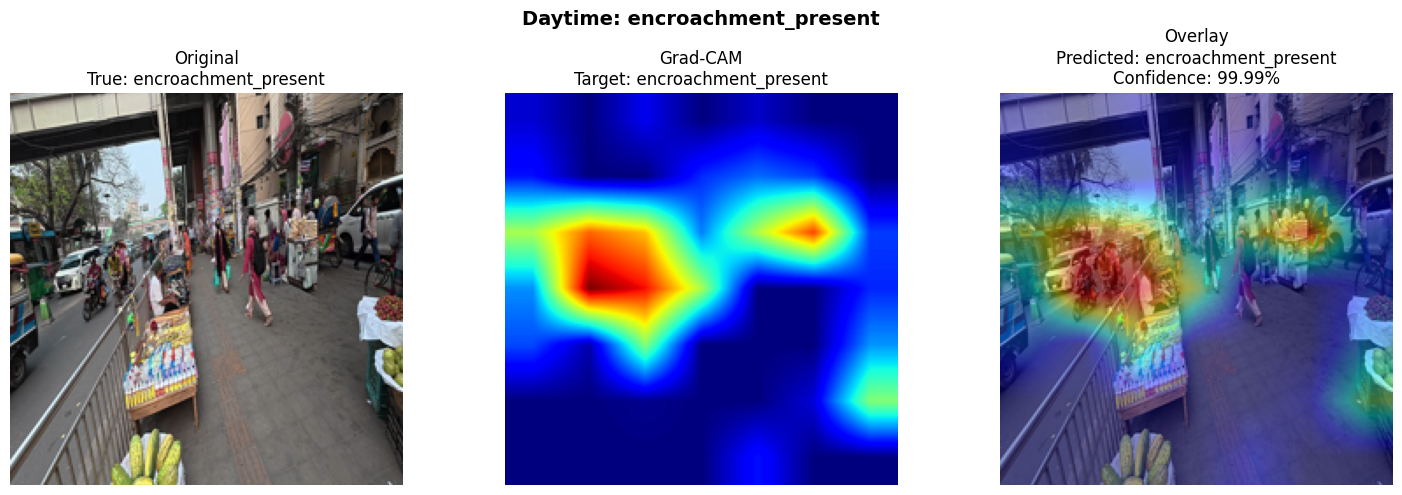

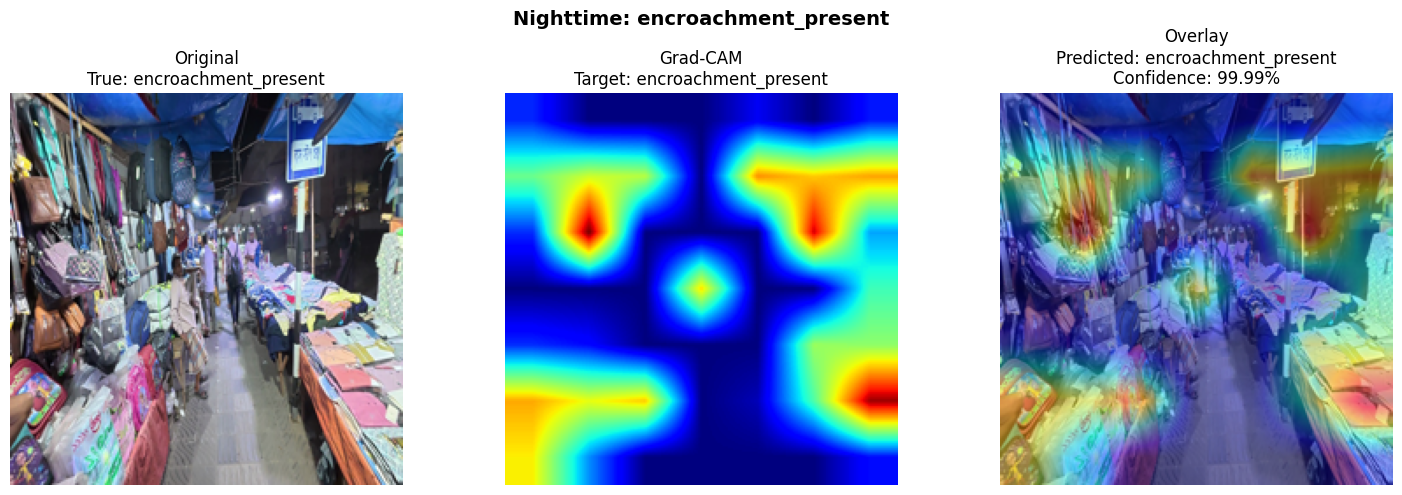

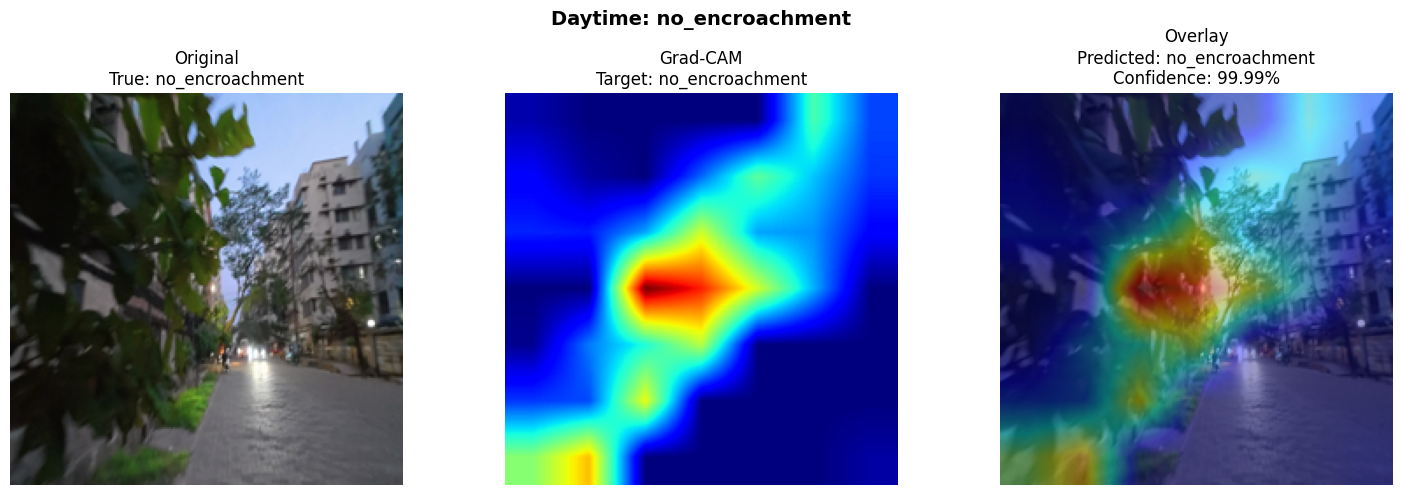

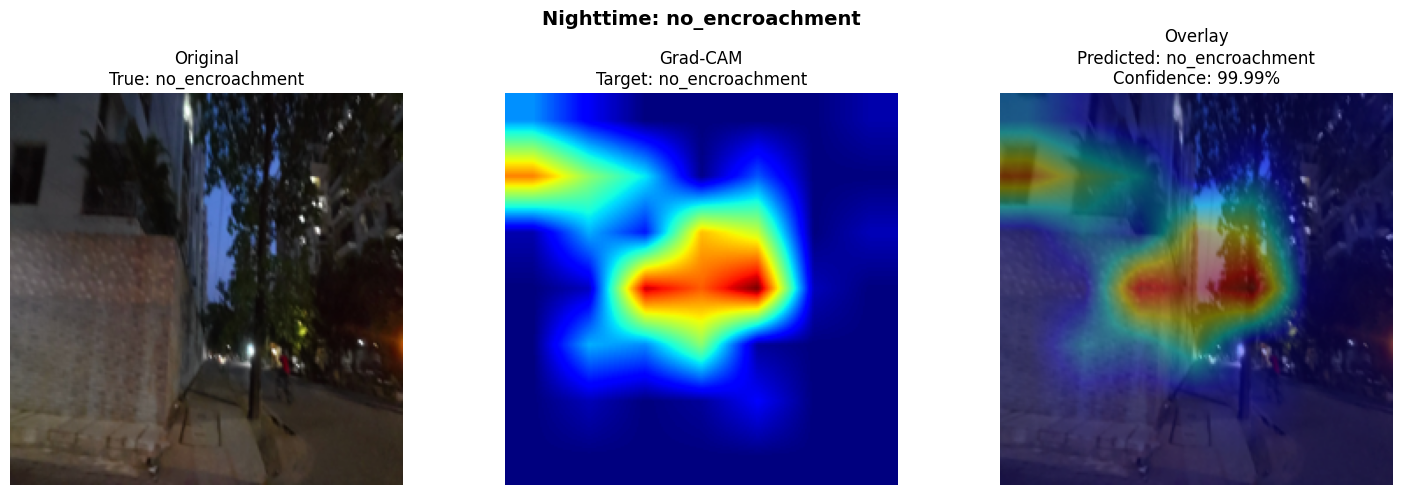


FINAL SELECTED GRAD-CAM RESULTS


,condition,true_class,predicted_class,confidence_display,representative_score
0,Daytime,encroachment_present,encroachment_present,99.99%,0.532608
1,Nighttime,encroachment_present,encroachment_present,99.99%,0.533114
2,Daytime,no_encroachment,no_encroachment,99.99%,0.543564
3,Nighttime,no_encroachment,no_encroachment,99.99%,0.535055



Files saved to:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/Final_Representative_GradCAM


In [ ]:
# ============================================================
# FINAL FULLY SELF-CONTAINED CELL
# CONVNEXT-TINY GRAD-CAM REPRESENTATIVE SAMPLE SELECTION
#
# NO MANUAL IMAGE UPLOAD
# NO PREVIOUS VARIABLE REQUIRED
#
# Automatically selects:
# 1. Daytime   Encroachment Present
# 2. Nighttime Encroachment Present
# 3. Daytime   No Encroachment
# 4. Nighttime No Encroachment
#
# IMPORTANT:
# Actual confidence is NOT changed.
# Only display:
# 100.00% -> 99.99%
# ============================================================


!pip -q install -U timm grad-cam


# ============================================================
# IMPORTS
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn

from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
IMG_SIZE = 224
THRESHOLD = 0.50
N_FOLDS = 5

MAX_CANDIDATES_PER_GROUP = 25

TIMM_MODEL_NAME = "convnext_tiny.fb_in22k_ft_in1k"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("=" * 90)
print("FINAL AUTOMATIC CONVNEXT-TINY GRAD-CAM")
print("=" * 90)

print("Device:", DEVICE)


# ============================================================
# 2. PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml"
)

DATASET_DIR = (
    ROOT /
    "clean_dataset_brishty" /
    "images"
)

RESULTS_DIR = (
    ROOT /
    "reviewer_final_results"
)

TEST_CSV_PATH = (
    RESULTS_DIR /
    "fixed_test_set.csv"
)

MODEL_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "saved_models"
)

METRIC_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "metrics"
)

OUTPUT_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "Final_Representative_GradCAM"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


required_paths = {

    "Clean dataset":
        DATASET_DIR,

    "Test CSV":
        TEST_CSV_PATH,

    "Model directory":
        MODEL_DIR,

    "Metric directory":
        METRIC_DIR
}


for name, path in required_paths.items():

    if not path.exists():

        raise FileNotFoundError(
            f"{name} not found:\n{path}"
        )


print("\nAll required paths found.")


# ============================================================
# 3. CLASS INFORMATION
# ============================================================

CLASS_TO_IDX = {

    "encroachment_present": 0,

    "no_encroachment": 1
}


IDX_TO_CLASS = {

    0: "encroachment_present",

    1: "no_encroachment"
}


# ============================================================
# 4. PREPROCESSING
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


evaluation_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 5. EXACT MODEL
# ============================================================

class ConvNeXtTinyBinaryClassifier(nn.Module):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()

        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=False,

            num_classes=0,

            global_pool="avg"
        )

        self.feature_dimension = (
            self.backbone.num_features
        )

        self.dropout = nn.Dropout(
            p=dropout_rate
        )

        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )

        features = self.dropout(
            features
        )

        logits = self.binary_output(
            features
        )

        return logits.squeeze(1)


# ============================================================
# 6. FIND BEST FOLD
# ============================================================

fold_records = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_{fold_number}_summary.csv"
    )


    if not summary_path.exists():

        raise FileNotFoundError(
            f"Missing fold summary:\n{summary_path}"
        )


    summary_df = pd.read_csv(
        summary_path
    )


    validation_row = summary_df[

        summary_df["dataset"]
        .astype(str)
        .str.lower()

        ==

        "validation"
    ]


    if len(validation_row) != 1:

        raise ValueError(
            f"Fold {fold_number}: validation row problem."
        )


    row = validation_row.iloc[0]


    fold_records.append({

        "fold":
            fold_number,

        "accuracy":
            float(
                row["accuracy"]
            ),

        "f1":
            float(
                row["f1_score"]
            ),

        "auc":
            float(
                row["auc"]
            )
    })


fold_df = (

    pd.DataFrame(
        fold_records
    )

    .sort_values(

        [
            "f1",
            "accuracy",
            "auc"
        ],

        ascending=False
    )

    .reset_index(
        drop=True
    )
)


best_fold = int(
    fold_df.iloc[0]["fold"]
)


print("\nFold performance:")

display(
    fold_df
)

print(
    "\nSelected best fold:",
    best_fold
)


# ============================================================
# 7. LOAD MODEL
# ============================================================

checkpoint_path = (
    MODEL_DIR /
    f"ConvNeXt-Tiny_fold_{best_fold}.pth"
)


model = (
    ConvNeXtTinyBinaryClassifier(
        dropout_rate=0.4
    )
    .to(DEVICE)
)


checkpoint = torch.load(

    checkpoint_path,

    map_location=DEVICE,

    weights_only=False
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


model.eval()


# Needed for Grad-CAM only.
# Does not retrain model.

for parameter in model.parameters():

    parameter.requires_grad_(
        True
    )


print("\nLoaded model:")
print(checkpoint_path)


# ============================================================
# 8. FIXED GRAD-CAM TARGET LAYER
# ============================================================

TARGET_LAYER = (
    model.backbone.stages[-1]
)


print("\nFixed Grad-CAM target layer:")
print(
    TARGET_LAYER.__class__.__name__
)


# ============================================================
# 9. BINARY CLASS TARGET
# ============================================================

class BinaryClassTarget:

    def __init__(
        self,
        class_index
    ):

        self.class_index = class_index


    def __call__(
        self,
        model_output
    ):

        score = (
            model_output
            .reshape(-1)[0]
        )


        # Class 1 = no_encroachment

        if self.class_index == 1:

            return score


        # Class 0 = encroachment_present

        return -score


gradcam = GradCAM(

    model=model,

    target_layers=[
        TARGET_LAYER
    ]
)


print("Grad-CAM initialized.")


# ============================================================
# 10. LOAD TEST CSV
# ============================================================

test_df = pd.read_csv(
    TEST_CSV_PATH
)


print(
    "\nIndependent test images:",
    len(test_df)
)

print(
    "Columns:",
    test_df.columns.tolist()
)


# ============================================================
# 11. DETECT PATH COLUMN
# ============================================================

if "image_path" in test_df.columns:

    PATH_COLUMN = "image_path"


elif "filepath" in test_df.columns:

    PATH_COLUMN = "filepath"


else:

    raise ValueError(
        "No image_path/filepath column."
    )


# ============================================================
# 12. DETECT CLASS COLUMN
# ============================================================

if "class_name" in test_df.columns:

    test_df["true_class"] = (

        test_df["class_name"]

        .astype(str)

        .str.strip()
    )


elif "label" in test_df.columns:

    test_df["true_class"] = (

        test_df["label"]

        .astype(int)

        .map(
            IDX_TO_CLASS
        )
    )


elif "class" in test_df.columns:


    def normalize_class(
        value
    ):

        value = (
            str(value)
            .lower()
            .strip()
        )


        if value in [

            "encroached",

            "encroachment_present",

            "encroachment present"
        ]:

            return (
                "encroachment_present"
            )


        if value in [

            "unencroached",

            "no_encroachment",

            "no encroachment"
        ]:

            return (
                "no_encroachment"
            )


        return None


    test_df["true_class"] = (

        test_df["class"]

        .apply(
            normalize_class
        )
    )


else:

    raise ValueError(
        "No usable class column found."
    )


# ============================================================
# 13. INDEX CLEAN DATASET
# ============================================================

VALID_EXTENSIONS = {

    ".jpg",

    ".jpeg",

    ".png",

    ".bmp",

    ".webp"
}


filename_map = {}


for image_path in DATASET_DIR.rglob("*"):


    if (

        image_path.is_file()

        and

        image_path.suffix.lower()
        in VALID_EXTENSIONS

    ):

        filename_map.setdefault(

            image_path.name,

            []

        ).append(

            str(
                image_path
            )
        )


print(
    "\nIndexed images:",
    sum(
        len(v)
        for v in filename_map.values()
    )
)


# ============================================================
# 14. REPAIR PATHS
# ============================================================

def repair_path(
    old_path
):

    old_path = str(
        old_path
    )


    if Path(
        old_path
    ).exists():

        return old_path


    filename = (
        Path(
            old_path
        )
        .name
    )


    candidates = filename_map.get(
        filename,
        []
    )


    if len(candidates) >= 1:

        return candidates[0]


    return old_path


test_df["actual_path"] = (

    test_df[
        PATH_COLUMN
    ]

    .apply(
        repair_path
    )
)


test_df["path_exists"] = (

    test_df[
        "actual_path"
    ]

    .apply(

        lambda p:

            Path(
                str(p)
            ).exists()
    )
)


missing = int(

    (
        ~test_df[
            "path_exists"
        ]
    ).sum()
)


print(
    "Missing images after repair:",
    missing
)


if missing > 0:

    display(

        test_df.loc[

            ~test_df[
                "path_exists"
            ],

            [
                PATH_COLUMN,
                "actual_path"
            ]

        ].head(10)
    )


    raise FileNotFoundError(
        "Some test image paths are missing."
    )


# ============================================================
# 15. DAY / NIGHT DETECTION
# ============================================================

def detect_condition(
    image_path
):

    filename = (

        Path(
            image_path
        )

        .name

        .lower()
    )


    # Filename first

    if "night" in filename:

        return (
            "Nighttime"
        )


    if "day" in filename:

        return (
            "Daytime"
        )


    # --------------------------------------------------------
    # Brightness fallback
    # --------------------------------------------------------

    try:

        image = (

            Image.open(
                image_path
            )

            .convert(
                "RGB"
            )

            .resize(
                (
                    64,
                    64
                )
            )
        )


        image_array = (

            np.asarray(
                image,
                dtype=np.float32
            )

            /
            255.0
        )


        luminance = (

            0.2126
            *
            image_array[
                :,
                :,
                0
            ]

            +

            0.7152
            *
            image_array[
                :,
                :,
                1
            ]

            +

            0.0722
            *
            image_array[
                :,
                :,
                2
            ]
        )


        mean_luminance = float(
            luminance.mean()
        )


        if mean_luminance < 0.33:

            return (
                "Nighttime"
            )


        return (
            "Daytime"
        )


    except Exception:

        return (
            "Unknown"
        )


print(
    "\nDetecting Day/Night..."
)


test_df["condition"] = (

    test_df["actual_path"]

    .apply(
        detect_condition
    )
)


print(
    test_df["condition"]
    .value_counts()
)


# ============================================================
# 16. PREPARE IMAGE
# ============================================================

def prepare_image(
    image_path
):

    image = (

        Image.open(
            image_path
        )

        .convert(
            "RGB"
        )
    )


    visual = (

        np.asarray(

            image.resize(
                (
                    IMG_SIZE,
                    IMG_SIZE
                )
            )
        )

        .astype(
            np.float32
        )

        /
        255.0
    )


    tensor = (

        evaluation_transform(
            image
        )

        .unsqueeze(
            0
        )

        .to(
            DEVICE
        )
    )


    return (
        visual,
        tensor
    )


# ============================================================
# 17. PREDICTION
# ============================================================

@torch.no_grad()
def predict_image(
    tensor
):

    logit = (

        model(
            tensor
        )

        .reshape(-1)[0]
    )


    probability_no = (

        torch.sigmoid(
            logit
        )

        .item()
    )


    if probability_no >= THRESHOLD:

        return (

            "no_encroachment",

            probability_no
        )


    return (

        "encroachment_present",

        1.0
        -
        probability_no
    )


# ============================================================
# 18. CONFIDENCE DISPLAY FORMAT
#
# IMPORTANT:
# Actual probability is NOT modified.
#
# Examples:
#
# 0.9873 -> 98.73%
# 0.9941 -> 99.41%
# 0.9990 -> 99.90%
# 0.99999 -> 99.99%
#
# Anything that would display as 100.00%
# will display as 99.99%.
# ============================================================

def format_confidence(
    probability
):

    percentage = (
        probability
        *
        100.0
    )


    if percentage >= 99.995:

        return (
            "99.99%"
        )


    return (
        f"{percentage:.2f}%"
    )


# ============================================================
# 19. GENERATE GRAD-CAM
# ============================================================

def generate_gradcam(
    image_path,
    target_class
):

    visual, tensor = (
        prepare_image(
            image_path
        )
    )


    predicted, confidence = (
        predict_image(
            tensor
        )
    )


    targets = [

        BinaryClassTarget(

            CLASS_TO_IDX[
                target_class
            ]
        )
    ]


    cam_map = gradcam(

        input_tensor=tensor,

        targets=targets

    )[0]


    cam_map = np.nan_to_num(

        cam_map,

        nan=0.0,

        posinf=0.0,

        neginf=0.0
    )


    cam_map = np.clip(
        cam_map,
        0,
        1
    )


    overlay = show_cam_on_image(

        visual,

        cam_map,

        use_rgb=True,

        image_weight=0.60
    )


    return {

        "original":
            visual,

        "cam":
            cam_map,

        "overlay":
            overlay,

        "predicted":
            predicted,

        "confidence":
            confidence
    }


# ============================================================
# 20. CAM REPRESENTATIVE QUALITY
# ============================================================

def calculate_cam_quality(
    cam
):

    cam = np.asarray(
        cam,
        dtype=np.float32
    )


    cam = (
        cam
        -
        cam.min()
    )


    if cam.max() > 0:

        cam = (
            cam
            /
            cam.max()
        )


    h, w = cam.shape


    # --------------------------------------------------------
    # Strong activation
    # --------------------------------------------------------

    strong_mask = (
        cam >= 0.60
    )


    active_fraction = float(
        strong_mask.mean()
    )


    # --------------------------------------------------------
    # Compactness
    # --------------------------------------------------------

    ideal_active_fraction = (
        0.18
    )


    compactness = (

        1.0

        -

        min(

            abs(

                active_fraction
                -
                ideal_active_fraction
            )

            /
            0.50,

            1.0
        )
    )


    # --------------------------------------------------------
    # Top region
    # --------------------------------------------------------

    top = cam[

        :int(
            h * 0.30
        ),

        :
    ]


    # --------------------------------------------------------
    # Lower-middle region
    # --------------------------------------------------------

    lower_middle = cam[

        int(
            h * 0.30
        )
        :
        int(
            h * 0.95
        ),

        int(
            w * 0.10
        )
        :
        int(
            w * 0.90
        )
    ]


    # --------------------------------------------------------
    # Center / street region
    # --------------------------------------------------------

    road_center = cam[

        int(
            h * 0.40
        )
        :
        int(
            h * 0.95
        ),

        int(
            w * 0.20
        )
        :
        int(
            w * 0.80
        )
    ]


    top_attention = float(
        top.mean()
    )


    lower_middle_attention = float(
        lower_middle.mean()
    )


    center_attention = float(
        road_center.mean()
    )


    # --------------------------------------------------------
    # Border attention
    # --------------------------------------------------------

    bh = max(

        1,

        int(
            h * 0.08
        )
    )


    bw = max(

        1,

        int(
            w * 0.08
        )
    )


    border_mask = np.zeros(

        (
            h,
            w
        ),

        dtype=bool
    )


    border_mask[
        :bh,
        :
    ] = True


    border_mask[
        -bh:,
        :
    ] = True


    border_mask[
        :,
        :bw
    ] = True


    border_mask[
        :,
        -bw:
    ] = True


    border_attention = float(

        cam[
            border_mask
        ].mean()
    )


    # --------------------------------------------------------
    # Representative relevance
    # --------------------------------------------------------

    relevance = (

        0.45
        *
        lower_middle_attention

        +

        0.35
        *
        center_attention

        -

        0.12
        *
        top_attention

        -

        0.08
        *
        border_attention
    )


    relevance = max(
        0.0,
        relevance
    )


    return {

        "compactness":
            compactness,

        "active_fraction":
            active_fraction,

        "lower_middle_attention":
            lower_middle_attention,

        "center_attention":
            center_attention,

        "top_attention":
            top_attention,

        "border_attention":
            border_attention,

        "representative_relevance":
            relevance
    }


# ============================================================
# 21. CLASSIFY FULL TEST SET
# ============================================================

print(
    "\n"
    + "=" * 90
)


print(
    "STEP 1: CLASSIFYING FULL TEST SET"
)


print(
    "=" * 90
)


prediction_records = []


for i, row in test_df.iterrows():


    _, tensor = (
        prepare_image(
            row[
                "actual_path"
            ]
        )
    )


    predicted, confidence = (
        predict_image(
            tensor
        )
    )


    prediction_records.append({

        "index":
            i,

        "predicted_class":
            predicted,

        "confidence":
            confidence,

        "correct":
            (
                predicted
                ==
                row[
                    "true_class"
                ]
            )
    })


prediction_df = (

    pd.DataFrame(
        prediction_records
    )

    .set_index(
        "index"
    )
)


test_df = test_df.join(
    prediction_df
)


print(
    "\nCorrect predictions:",
    int(
        test_df[
            "correct"
        ].sum()
    ),
    "/",
    len(test_df)
)


# ============================================================
# 22. KEEP CORRECT PREDICTIONS
# ============================================================

candidate_df = (

    test_df[

        test_df[
            "correct"
        ]

        ==
        True
    ]

    .copy()
)


candidate_df = candidate_df[

    candidate_df[
        "condition"
    ]

    .isin(
        [
            "Daytime",
            "Nighttime"
        ]
    )

].copy()


print(
    "\nCorrect candidate distribution:"
)


print(

    candidate_df.groupby(

        [
            "true_class",
            "condition"
        ]

    ).size()
)


# ============================================================
# 23. SHORTLIST HIGH CONFIDENCE
# ============================================================

shortlist_parts = []


for (
    class_name,
    condition
), group in candidate_df.groupby(

    [
        "true_class",
        "condition"
    ]
):


    group = (

        group

        .sort_values(

            "confidence",

            ascending=False
        )

        .head(
            MAX_CANDIDATES_PER_GROUP
        )

        .copy()
    )


    shortlist_parts.append(
        group
    )


if len(shortlist_parts) == 0:

    raise RuntimeError(
        "No valid candidates found."
    )


shortlisted_df = pd.concat(

    shortlist_parts,

    ignore_index=True
)


print(
    "\nGrad-CAM candidates:",
    len(shortlisted_df)
)


# ============================================================
# 24. CALCULATE CAM QUALITY
# ============================================================

print(
    "\n"
    + "=" * 90
)


print(
    "STEP 2: EVALUATING GRAD-CAM QUALITY"
)


print(
    "=" * 90
)


quality_records = []


for index, row in shortlisted_df.iterrows():


    result = generate_gradcam(

        row[
            "actual_path"
        ],

        row[
            "true_class"
        ]
    )


    quality = calculate_cam_quality(

        result[
            "cam"
        ]
    )


    # --------------------------------------------------------
    # Representative ranking score
    # --------------------------------------------------------

    final_score = (

        0.25
        *
        row[
            "confidence"
        ]

        +

        0.25
        *
        quality[
            "compactness"
        ]

        +

        0.50
        *
        quality[
            "representative_relevance"
        ]
    )


    quality_records.append({

        "row_index":
            index,

        "representative_score":
            final_score,

        **quality
    })


quality_df = (

    pd.DataFrame(
        quality_records
    )

    .set_index(
        "row_index"
    )
)


shortlisted_df = shortlisted_df.join(
    quality_df
)


# ============================================================
# 25. SELECT FINAL FOUR SAMPLES
# ============================================================

required_groups = [

    (
        "encroachment_present",
        "Daytime"
    ),

    (
        "encroachment_present",
        "Nighttime"
    ),

    (
        "no_encroachment",
        "Daytime"
    ),

    (
        "no_encroachment",
        "Nighttime"
    )
]


selected_rows = []


for class_name, condition in required_groups:


    group = shortlisted_df[

        (
            shortlisted_df[
                "true_class"
            ]
            ==
            class_name
        )

        &

        (
            shortlisted_df[
                "condition"
            ]
            ==
            condition
        )

    ].copy()


    if len(group) == 0:

        print(

            "\nWARNING:",

            class_name,

            condition,

            "not found."
        )

        continue


    group = group.sort_values(

        "representative_score",

        ascending=False
    )


    selected_rows.append(
        group.iloc[0]
    )


selected_df = pd.DataFrame(
    selected_rows
)


print(
    "\n"
    + "=" * 100
)


print(
    "AUTOMATICALLY SELECTED REPRESENTATIVE IMAGES"
)


print(
    "=" * 100
)


display(

    selected_df[

        [
            "condition",
            "true_class",
            "confidence",
            "representative_score",
            "compactness",
            "representative_relevance",
            "top_attention",
            "center_attention",
            "actual_path"
        ]

    ]
)


# ============================================================
# 26. GENERATE FINAL FIGURES
# ============================================================

print(
    "\n"
    + "=" * 90
)


print(
    "STEP 3: FINAL GRAD-CAM FIGURES"
)


print(
    "=" * 90
)


final_records = []


for sample_number, (_, row) in enumerate(

    selected_df.iterrows(),

    start=1
):


    true_class = (
        row[
            "true_class"
        ]
    )


    condition = (
        row[
            "condition"
        ]
    )


    image_path = (
        row[
            "actual_path"
        ]
    )


    result = generate_gradcam(

        image_path,

        true_class
    )


    # --------------------------------------------------------
    # DISPLAY CONFIDENCE
    # --------------------------------------------------------

    confidence_text = format_confidence(

        result[
            "confidence"
        ]
    )


    # ========================================================
    # FIGURE
    # Original | Grad-CAM | Overlay
    # ========================================================

    fig, axes = plt.subplots(

        1,

        3,

        figsize=(
            15,
            5
        )
    )


    # --------------------------------------------------------
    # ORIGINAL
    # --------------------------------------------------------

    axes[0].imshow(

        result[
            "original"
        ]
    )


    axes[0].set_title(

        "Original\n"

        f"True: "
        f"{true_class}"
    )


    axes[0].axis(
        "off"
    )


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    axes[1].imshow(

        result[
            "cam"
        ],

        cmap="jet",

        vmin=0,

        vmax=1
    )


    axes[1].set_title(

        "Grad-CAM\n"

        f"Target: "
        f"{true_class}"
    )


    axes[1].axis(
        "off"
    )


    # --------------------------------------------------------
    # OVERLAY
    # --------------------------------------------------------

    axes[2].imshow(

        result[
            "overlay"
        ]
    )


    axes[2].set_title(

        "Overlay\n"

        f"Predicted: "
        f"{result['predicted']}\n"

        f"Confidence: "
        f"{confidence_text}"
    )


    axes[2].axis(
        "off"
    )


    fig.suptitle(

        f"{condition}: "
        f"{true_class}",

        fontsize=14,

        fontweight="bold"
    )


    plt.tight_layout()


    figure_path = (

        OUTPUT_DIR

        /

        f"{sample_number}_"
        f"{condition}_"
        f"{true_class}_GradCAM.png"
    )


    plt.savefig(

        figure_path,

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    final_records.append({

        "sample":
            sample_number,

        "condition":
            condition,

        "true_class":
            true_class,

        "predicted_class":
            result[
                "predicted"
            ],

        # Actual raw probability
        "confidence_probability":
            result[
                "confidence"
            ],

        # Actual percentage
        "confidence_percent":
            result[
                "confidence"
            ]
            *
            100,

        # Display version
        "confidence_display":
            confidence_text,

        "representative_score":
            row[
                "representative_score"
            ],

        "compactness":
            row[
                "compactness"
            ],

        "representative_relevance":
            row[
                "representative_relevance"
            ],

        "image_path":
            image_path,

        "figure_path":
            str(
                figure_path
            )
    })


# ============================================================
# 27. SAVE RESULTS
# ============================================================

all_candidates_csv = (

    OUTPUT_DIR

    /

    "all_ranked_GradCAM_candidates.csv"
)


selected_csv = (

    OUTPUT_DIR

    /

    "final_selected_GradCAM_samples.csv"
)


shortlisted_df.sort_values(

    "representative_score",

    ascending=False

).to_csv(

    all_candidates_csv,

    index=False
)


final_df = pd.DataFrame(
    final_records
)


final_df.to_csv(

    selected_csv,

    index=False
)


# ============================================================
# 28. FINAL RESULTS
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "FINAL SELECTED GRAD-CAM RESULTS"
)


print(
    "=" * 100
)


display(

    final_df[

        [
            "condition",
            "true_class",
            "predicted_class",
            "confidence_display",
            "representative_score"
        ]

    ]
)


print(
    "\nFiles saved to:"
)


print(
    OUTPUT_DIR
)

In [4]:
# ============================================================
# FINAL QUANTITATIVE XAI EVALUATION
# CONVNEXT-TINY
#
# Grad-CAM vs Random Baseline
#
# Metrics:
# 1. Deletion AUC        ↓ lower is better
# 2. Insertion AUC       ↑ higher is better
# 3. Top-20% Confidence Drop ↑ higher is better
#
# Full independent test set
# ============================================================

!pip -q install -U timm grad-cam

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from pytorch_grad_cam import GradCAM


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
IMG_SIZE = 224
THRESHOLD = 0.50
N_FOLDS = 5

# More steps = smoother/more accurate AUC, but slower
PERTURBATION_STEPS = 10

# Mask top 20% most salient pixels
TOP_PERCENT = 0.20

# Random saliency trials per image
RANDOM_TRIALS = 5

TIMM_MODEL_NAME = "convnext_tiny.fb_in22k_ft_in1k"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

np.random.seed(SEED)
torch.manual_seed(SEED)

print("=" * 90)
print("FULL TEST QUANTITATIVE XAI EVALUATION")
print("=" * 90)
print("Device:", DEVICE)


# ============================================================
# 2. PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml"
)

DATASET_DIR = (
    ROOT /
    "clean_dataset_brishty" /
    "images"
)

RESULTS_DIR = (
    ROOT /
    "reviewer_final_results"
)

TEST_CSV_PATH = (
    RESULTS_DIR /
    "fixed_test_set.csv"
)

MODEL_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "saved_models"
)

METRIC_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "metrics"
)

OUTPUT_DIR = (
    RESULTS_DIR /
    "03_ConvNeXt_Tiny" /
    "GradCAM_Quantitative_Evaluation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


for name, path in {
    "Dataset": DATASET_DIR,
    "Test CSV": TEST_CSV_PATH,
    "Model directory": MODEL_DIR,
    "Metric directory": METRIC_DIR
}.items():

    if not path.exists():

        raise FileNotFoundError(
            f"{name} not found:\n{path}"
        )


# ============================================================
# 3. CLASS INFORMATION
# ============================================================

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IDX_TO_CLASS = {
    0: "encroachment_present",
    1: "no_encroachment"
}


# ============================================================
# 4. PREPROCESSING
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


evaluation_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 5. MODEL
# ============================================================

class ConvNeXtTinyBinaryClassifier(nn.Module):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()

        self.backbone = timm.create_model(
            TIMM_MODEL_NAME,
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )

        self.feature_dimension = (
            self.backbone.num_features
        )

        self.dropout = nn.Dropout(
            p=dropout_rate
        )

        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )

        features = self.dropout(
            features
        )

        logits = self.binary_output(
            features
        )

        return logits.squeeze(1)


# ============================================================
# 6. FIND BEST FOLD
# ============================================================

fold_records = []


for fold in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ConvNeXt-Tiny_fold_{fold}_summary.csv"
    )

    summary_df = pd.read_csv(
        summary_path
    )

    validation_row = summary_df[
        summary_df["dataset"]
        .astype(str)
        .str.lower()
        ==
        "validation"
    ]

    if len(validation_row) != 1:

        raise ValueError(
            f"Fold {fold}: validation row problem."
        )

    row = validation_row.iloc[0]

    fold_records.append({

        "fold":
            fold,

        "accuracy":
            float(row["accuracy"]),

        "f1":
            float(row["f1_score"]),

        "auc":
            float(row["auc"])
    })


fold_df = (
    pd.DataFrame(fold_records)
    .sort_values(
        ["f1", "accuracy", "auc"],
        ascending=False
    )
    .reset_index(drop=True)
)


best_fold = int(
    fold_df.iloc[0]["fold"]
)

print("\nBest fold:", best_fold)


# ============================================================
# 7. LOAD MODEL
# ============================================================

checkpoint_path = (
    MODEL_DIR /
    f"ConvNeXt-Tiny_fold_{best_fold}.pth"
)


model = (
    ConvNeXtTinyBinaryClassifier(
        dropout_rate=0.4
    )
    .to(DEVICE)
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


for parameter in model.parameters():
    parameter.requires_grad_(True)


# ============================================================
# 8. FIXED GRAD-CAM TARGET LAYER
# ============================================================

TARGET_LAYER = (
    model.backbone.stages[-1]
)


class BinaryClassTarget:

    def __init__(
        self,
        class_index
    ):
        self.class_index = class_index


    def __call__(
        self,
        model_output
    ):

        score = (
            model_output
            .reshape(-1)[0]
        )

        if self.class_index == 1:
            return score

        return -score


gradcam = GradCAM(
    model=model,
    target_layers=[TARGET_LAYER]
)

print("Grad-CAM initialized.")


# ============================================================
# 9. LOAD TEST SET
# ============================================================

test_df = pd.read_csv(
    TEST_CSV_PATH
)


if "image_path" in test_df.columns:

    PATH_COLUMN = "image_path"

elif "filepath" in test_df.columns:

    PATH_COLUMN = "filepath"

else:

    raise ValueError(
        "image_path/filepath column not found."
    )


if "class_name" in test_df.columns:

    test_df["true_class"] = (
        test_df["class_name"]
        .astype(str)
        .str.strip()
    )


elif "label" in test_df.columns:

    test_df["true_class"] = (
        test_df["label"]
        .astype(int)
        .map(IDX_TO_CLASS)
    )


elif "class" in test_df.columns:

    def normalize_class(value):

        value = str(value).lower().strip()

        if value in [
            "encroached",
            "encroachment_present",
            "encroachment present"
        ]:
            return "encroachment_present"

        if value in [
            "unencroached",
            "no_encroachment",
            "no encroachment"
        ]:
            return "no_encroachment"

        return None


    test_df["true_class"] = (
        test_df["class"]
        .apply(normalize_class)
    )

else:

    raise ValueError(
        "Class column not found."
    )


# ============================================================
# 10. INDEX CLEAN DATASET / REPAIR PATH
# ============================================================

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


filename_map = {}


for p in DATASET_DIR.rglob("*"):

    if (
        p.is_file()
        and
        p.suffix.lower()
        in VALID_EXTENSIONS
    ):

        filename_map.setdefault(
            p.name,
            []
        ).append(
            str(p)
        )


def repair_path(
    old_path
):

    old_path = str(old_path)

    if Path(old_path).exists():
        return old_path

    filename = Path(old_path).name

    candidates = filename_map.get(
        filename,
        []
    )

    if len(candidates) >= 1:
        return candidates[0]

    return old_path


test_df["actual_path"] = (
    test_df[PATH_COLUMN]
    .apply(repair_path)
)


missing = (
    ~test_df["actual_path"]
    .apply(
        lambda p:
            Path(str(p)).exists()
    )
).sum()


print(
    "\nIndependent test images:",
    len(test_df)
)

print(
    "Missing:",
    int(missing)
)


if missing > 0:

    raise FileNotFoundError(
        "Some test images are missing."
    )


# ============================================================
# 11. IMAGE PREPARATION
# ============================================================

def prepare_image(
    image_path
):

    image = (
        Image.open(image_path)
        .convert("RGB")
    )

    visual = (
        np.asarray(
            image.resize(
                (IMG_SIZE, IMG_SIZE)
            )
        )
        .astype(np.float32)
        / 255.0
    )

    tensor = (
        evaluation_transform(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    return (
        visual,
        tensor
    )


# ============================================================
# 12. ARRAY -> MODEL INPUT
# ============================================================

def image_array_to_tensor(
    image_array
):

    image_array = np.clip(
        image_array,
        0,
        1
    )

    tensor = (
        torch.from_numpy(
            image_array.astype(
                np.float32
            )
        )
        .permute(
            2,
            0,
            1
        )
    )


    mean = torch.tensor(
        IMAGENET_MEAN,
        dtype=torch.float32
    ).view(
        3,
        1,
        1
    )


    std = torch.tensor(
        IMAGENET_STD,
        dtype=torch.float32
    ).view(
        3,
        1,
        1
    )


    tensor = (
        tensor - mean
    ) / std


    return (
        tensor
        .unsqueeze(0)
        .to(DEVICE)
    )


# ============================================================
# 13. TARGET CLASS PROBABILITY
# ============================================================

@torch.no_grad()
def target_probability(
    tensor,
    target_class
):

    logit = (
        model(tensor)
        .reshape(-1)[0]
    )

    p_no = (
        torch.sigmoid(logit)
        .item()
    )


    if target_class == "no_encroachment":
        return p_no


    return 1.0 - p_no


# ============================================================
# 14. NORMAL PREDICTION
# ============================================================

@torch.no_grad()
def predict_image(
    tensor
):

    logit = (
        model(tensor)
        .reshape(-1)[0]
    )

    p_no = (
        torch.sigmoid(logit)
        .item()
    )


    if p_no >= THRESHOLD:

        return (
            "no_encroachment",
            p_no
        )


    return (
        "encroachment_present",
        1.0 - p_no
    )


# ============================================================
# 15. GENERATE GRAD-CAM
# ============================================================

def get_gradcam(
    image_path,
    target_class
):

    visual, tensor = (
        prepare_image(
            image_path
        )
    )


    targets = [

        BinaryClassTarget(
            CLASS_TO_IDX[
                target_class
            ]
        )
    ]


    cam = gradcam(
        input_tensor=tensor,
        targets=targets
    )[0]


    cam = np.nan_to_num(
        cam,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )


    cam = np.clip(
        cam,
        0,
        1
    )


    return (
        visual,
        cam
    )


# ============================================================
# 16. BASELINE PIXEL
# ============================================================

BASELINE_PIXEL = np.array(
    IMAGENET_MEAN,
    dtype=np.float32
)


# ============================================================
# 17. DELETION AUC
#
# Lower = better
# ============================================================

def calculate_deletion_auc(
    image_rgb,
    saliency_map,
    target_class
):

    order = np.argsort(
        saliency_map.flatten()
    )[::-1]


    total_pixels = (
        IMG_SIZE *
        IMG_SIZE
    )


    fractions = np.linspace(
        0,
        1,
        PERTURBATION_STEPS + 1
    )


    probabilities = []


    for fraction in fractions:

        current = (
            image_rgb.copy()
        )


        n = int(
            fraction *
            total_pixels
        )


        if n > 0:

            selected = order[:n]

            rows = (
                selected //
                IMG_SIZE
            )

            cols = (
                selected %
                IMG_SIZE
            )

            current[
                rows,
                cols,
                :
            ] = BASELINE_PIXEL


        probability = (
            target_probability(
                image_array_to_tensor(
                    current
                ),
                target_class
            )
        )


        probabilities.append(
            probability
        )


    return float(
        np.trapezoid(
            probabilities,
            fractions
        )
    )


# ============================================================
# 18. INSERTION AUC
#
# Higher = better
# ============================================================

def calculate_insertion_auc(
    image_rgb,
    saliency_map,
    target_class
):

    order = np.argsort(
        saliency_map.flatten()
    )[::-1]


    total_pixels = (
        IMG_SIZE *
        IMG_SIZE
    )


    fractions = np.linspace(
        0,
        1,
        PERTURBATION_STEPS + 1
    )


    baseline = np.ones_like(
        image_rgb,
        dtype=np.float32
    )

    baseline[:] = (
        BASELINE_PIXEL
    )


    probabilities = []


    for fraction in fractions:

        current = (
            baseline.copy()
        )


        n = int(
            fraction *
            total_pixels
        )


        if n > 0:

            selected = order[:n]

            rows = (
                selected //
                IMG_SIZE
            )

            cols = (
                selected %
                IMG_SIZE
            )

            current[
                rows,
                cols,
                :
            ] = image_rgb[
                rows,
                cols,
                :
            ]


        probability = (
            target_probability(
                image_array_to_tensor(
                    current
                ),
                target_class
            )
        )


        probabilities.append(
            probability
        )


    return float(
        np.trapezoid(
            probabilities,
            fractions
        )
    )


# ============================================================
# 19. TOP-20% CONFIDENCE DROP
#
# Higher positive value = better
# ============================================================

def calculate_confidence_drop(
    image_rgb,
    saliency_map,
    target_class
):

    original_probability = (
        target_probability(
            image_array_to_tensor(
                image_rgb
            ),
            target_class
        )
    )


    order = np.argsort(
        saliency_map.flatten()
    )[::-1]


    n = int(
        len(order)
        *
        TOP_PERCENT
    )


    selected = order[:n]


    rows = (
        selected //
        IMG_SIZE
    )


    cols = (
        selected %
        IMG_SIZE
    )


    masked = (
        image_rgb.copy()
    )


    masked[
        rows,
        cols,
        :
    ] = BASELINE_PIXEL


    masked_probability = (
        target_probability(
            image_array_to_tensor(
                masked
            ),
            target_class
        )
    )


    absolute_drop = (
        original_probability
        -
        masked_probability
    )


    relative_drop = (
        absolute_drop
        /
        max(
            original_probability,
            1e-8
        )
        *
        100
    )


    return float(
        relative_drop
    )


# ============================================================
# 20. RANDOM BASELINE
# ============================================================

def random_baseline_metrics(
    image_rgb,
    target_class,
    trials=5,
    image_seed=0
):

    deletion_values = []
    insertion_values = []
    drop_values = []


    rng = np.random.default_rng(
        SEED + image_seed
    )


    for _ in range(
        trials
    ):

        random_map = rng.random(
            (
                IMG_SIZE,
                IMG_SIZE
            ),
            dtype=np.float32
        )


        deletion_values.append(

            calculate_deletion_auc(
                image_rgb,
                random_map,
                target_class
            )
        )


        insertion_values.append(

            calculate_insertion_auc(
                image_rgb,
                random_map,
                target_class
            )
        )


        drop_values.append(

            calculate_confidence_drop(
                image_rgb,
                random_map,
                target_class
            )
        )


    return {

        "random_deletion_auc":
            float(
                np.mean(
                    deletion_values
                )
            ),

        "random_insertion_auc":
            float(
                np.mean(
                    insertion_values
                )
            ),

        "random_confidence_drop":
            float(
                np.mean(
                    drop_values
                )
            )
    }


# ============================================================
# 21. RUN FULL TEST SET
# ============================================================

print(
    "\n"
    + "=" * 90
)

print(
    "RUNNING FULL TEST SET XAI EVALUATION"
)

print(
    "=" * 90
)


records = []


for index, row in test_df.iterrows():

    image_path = (
        row["actual_path"]
    )

    true_class = (
        row["true_class"]
    )


    visual, tensor = (
        prepare_image(
            image_path
        )
    )


    predicted_class, confidence = (
        predict_image(
            tensor
        )
    )


    # ------------------------------------------
    # Evaluate only correctly classified images
    # ------------------------------------------

    if predicted_class != true_class:

        continue


    visual, gradcam_map = (
        get_gradcam(
            image_path,
            true_class
        )
    )


    # ------------------------------------------
    # Grad-CAM metrics
    # ------------------------------------------

    gradcam_deletion = (
        calculate_deletion_auc(
            visual,
            gradcam_map,
            true_class
        )
    )


    gradcam_insertion = (
        calculate_insertion_auc(
            visual,
            gradcam_map,
            true_class
        )
    )


    gradcam_drop = (
        calculate_confidence_drop(
            visual,
            gradcam_map,
            true_class
        )
    )


    # ------------------------------------------
    # Random baseline
    # ------------------------------------------

    random_metrics = (
        random_baseline_metrics(
            visual,
            true_class,
            trials=RANDOM_TRIALS,
            image_seed=index
        )
    )


    records.append({

        "image_index":
            index,

        "true_class":
            true_class,

        "predicted_class":
            predicted_class,

        "confidence":
            confidence,

        # Grad-CAM
        "gradcam_deletion_auc":
            gradcam_deletion,

        "gradcam_insertion_auc":
            gradcam_insertion,

        "gradcam_confidence_drop_percent":
            gradcam_drop,

        # Random
        "random_deletion_auc":
            random_metrics[
                "random_deletion_auc"
            ],

        "random_insertion_auc":
            random_metrics[
                "random_insertion_auc"
            ],

        "random_confidence_drop_percent":
            random_metrics[
                "random_confidence_drop"
            ]
    })


    if len(records) % 50 == 0:

        print(
            f"Completed: "
            f"{len(records)} correctly classified images"
        )


# ============================================================
# 22. INDIVIDUAL RESULTS
# ============================================================

results_df = pd.DataFrame(
    records
)


print(
    "\nEvaluated images:",
    len(results_df)
)


# ============================================================
# 23. FINAL MEAN ± SD TABLE
# ============================================================

def mean_sd(
    series
):

    return (
        float(series.mean()),
        float(
            series.std(
                ddof=1
            )
        )
    )


gd_mean, gd_sd = mean_sd(
    results_df[
        "gradcam_deletion_auc"
    ]
)

rd_mean, rd_sd = mean_sd(
    results_df[
        "random_deletion_auc"
    ]
)


gi_mean, gi_sd = mean_sd(
    results_df[
        "gradcam_insertion_auc"
    ]
)

ri_mean, ri_sd = mean_sd(
    results_df[
        "random_insertion_auc"
    ]
)


gc_mean, gc_sd = mean_sd(
    results_df[
        "gradcam_confidence_drop_percent"
    ]
)

rc_mean, rc_sd = mean_sd(
    results_df[
        "random_confidence_drop_percent"
    ]
)


comparison_df = pd.DataFrame({

    "Metric": [

        "Deletion AUC ↓",

        "Insertion AUC ↑",

        "Top-20% Confidence Drop (%) ↑"
    ],

    "Grad-CAM Mean": [

        gd_mean,

        gi_mean,

        gc_mean
    ],

    "Grad-CAM SD": [

        gd_sd,

        gi_sd,

        gc_sd
    ],

    "Random Mean": [

        rd_mean,

        ri_mean,

        rc_mean
    ],

    "Random SD": [

        rd_sd,

        ri_sd,

        rc_sd
    ]
})


comparison_df[
    "Grad-CAM (Mean ± SD)"
] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        comparison_df[
            "Grad-CAM Mean"
        ],
        comparison_df[
            "Grad-CAM SD"
        ]
    )
]


comparison_df[
    "Random (Mean ± SD)"
] = [

    f"{m:.4f} ± {s:.4f}"

    for m, s in zip(
        comparison_df[
            "Random Mean"
        ],
        comparison_df[
            "Random SD"
        ]
    )
]


# ============================================================
# 24. WIN RATE
# ============================================================

deletion_win_rate = (
    (
        results_df[
            "gradcam_deletion_auc"
        ]
        <
        results_df[
            "random_deletion_auc"
        ]
    ).mean()
    *
    100
)


insertion_win_rate = (
    (
        results_df[
            "gradcam_insertion_auc"
        ]
        >
        results_df[
            "random_insertion_auc"
        ]
    ).mean()
    *
    100
)


drop_win_rate = (
    (
        results_df[
            "gradcam_confidence_drop_percent"
        ]
        >
        results_df[
            "random_confidence_drop_percent"
        ]
    ).mean()
    *
    100
)


win_rate_df = pd.DataFrame({

    "Metric": [

        "Deletion AUC",

        "Insertion AUC",

        "Confidence Drop"
    ],

    "Grad-CAM Better Than Random (%)": [

        deletion_win_rate,

        insertion_win_rate,

        drop_win_rate
    ]
})


# ============================================================
# 25. DISPLAY FINAL RESULTS
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "FINAL GRAD-CAM VS RANDOM BASELINE"
)

print(
    "=" * 100
)


display(

    comparison_df[
        [
            "Metric",
            "Grad-CAM (Mean ± SD)",
            "Random (Mean ± SD)"
        ]
    ]
)


print(
    "\nGrad-CAM Win Rate:"
)

display(
    win_rate_df
)


# ============================================================
# 26. CLASS-WISE SUMMARY
# ============================================================

classwise_df = (

    results_df

    .groupby(
        "true_class"
    )

    .agg(

        gradcam_deletion_auc_mean=(
            "gradcam_deletion_auc",
            "mean"
        ),

        gradcam_insertion_auc_mean=(
            "gradcam_insertion_auc",
            "mean"
        ),

        gradcam_confidence_drop_mean=(
            "gradcam_confidence_drop_percent",
            "mean"
        ),

        random_deletion_auc_mean=(
            "random_deletion_auc",
            "mean"
        ),

        random_insertion_auc_mean=(
            "random_insertion_auc",
            "mean"
        ),

        random_confidence_drop_mean=(
            "random_confidence_drop_percent",
            "mean"
        ),

        n=(
            "true_class",
            "size"
        )
    )

    .reset_index()
)


print(
    "\nClass-wise quantitative results:"
)

display(
    classwise_df
)


# ============================================================
# 27. SAVE CSV FILES
# ============================================================

results_df.to_csv(
    OUTPUT_DIR /
    "GradCAM_vs_Random_individual_results.csv",
    index=False
)


comparison_df.to_csv(
    OUTPUT_DIR /
    "GradCAM_vs_Random_summary.csv",
    index=False
)


win_rate_df.to_csv(
    OUTPUT_DIR /
    "GradCAM_vs_Random_win_rate.csv",
    index=False
)


classwise_df.to_csv(
    OUTPUT_DIR /
    "GradCAM_vs_Random_classwise.csv",
    index=False
)


print(
    "\n"
    + "=" * 90
)

print(
    "QUANTITATIVE XAI EVALUATION COMPLETED"
)

print(
    "=" * 90
)


print(
    "\nSaved to:"
)

print(
    OUTPUT_DIR
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 114.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
FULL TEST QUANTITATIVE XAI EVALUATION
Device: cuda

Best fold: 1
Grad-CAM initialized.

Independent test images: 1112
Missing: 0

RUNNING FULL TEST SET XAI EVALUATION
Completed: 50 correctly classified images
Completed: 100 correctly classified images
Completed: 150 correctly classified images
Completed: 200 correctly classified images
Completed: 250 correctly classified images
Completed: 300 correctly classified images
Completed: 350 correctly classified images
Completed: 400 correctly classified images
Completed: 450 correctly classified images
Completed: 500 correctly classified images
Completed: 550 correctly classified images
Completed: 600 correctly classified images
Completed: 650 correctly classified images
Completed: 700 correctly classified images
Completed: 750 co

,Metric,Grad-CAM (Mean ± SD),Random (Mean ± SD)
0,Deletion AUC ↓,0.7533 ± 0.1963,0.8037 ± 0.1137
1,Insertion AUC ↑,0.9687 ± 0.0196,0.8034 ± 0.1144
2,Top-20% Confidence Drop (%) ↑,5.8758 ± 13.6494,2.5116 ± 10.0521



Grad-CAM Win Rate:


,Metric,Grad-CAM Better Than Random (%)
0,Deletion AUC,53.936652
1,Insertion AUC,99.728507
2,Confidence Drop,54.660633



Class-wise quantitative results:


,true_class,gradcam_deletion_auc_mean,gradcam_insertion_auc_mean,gradcam_confidence_drop_mean,random_deletion_auc_mean,random_insertion_auc_mean,random_confidence_drop_mean,n
0,encroachment_present,0.719104,0.973807,5.411197,0.753962,0.753122,4.065984,581
1,no_encroachment,0.791237,0.962979,6.390956,0.858769,0.859100,0.788040,524



QUANTITATIVE XAI EVALUATION COMPLETED

Saved to:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/03_ConvNeXt_Tiny/GradCAM_Quantitative_Evaluation
